In [1]:
import pandas as pd

df = pd.read_pickle("interactions_with_sequences_FINAL_NEW.pkl")


Shape: (82171, 31)
Final dataset size: 81847
Types retained: 13
Species pairs retained: 27


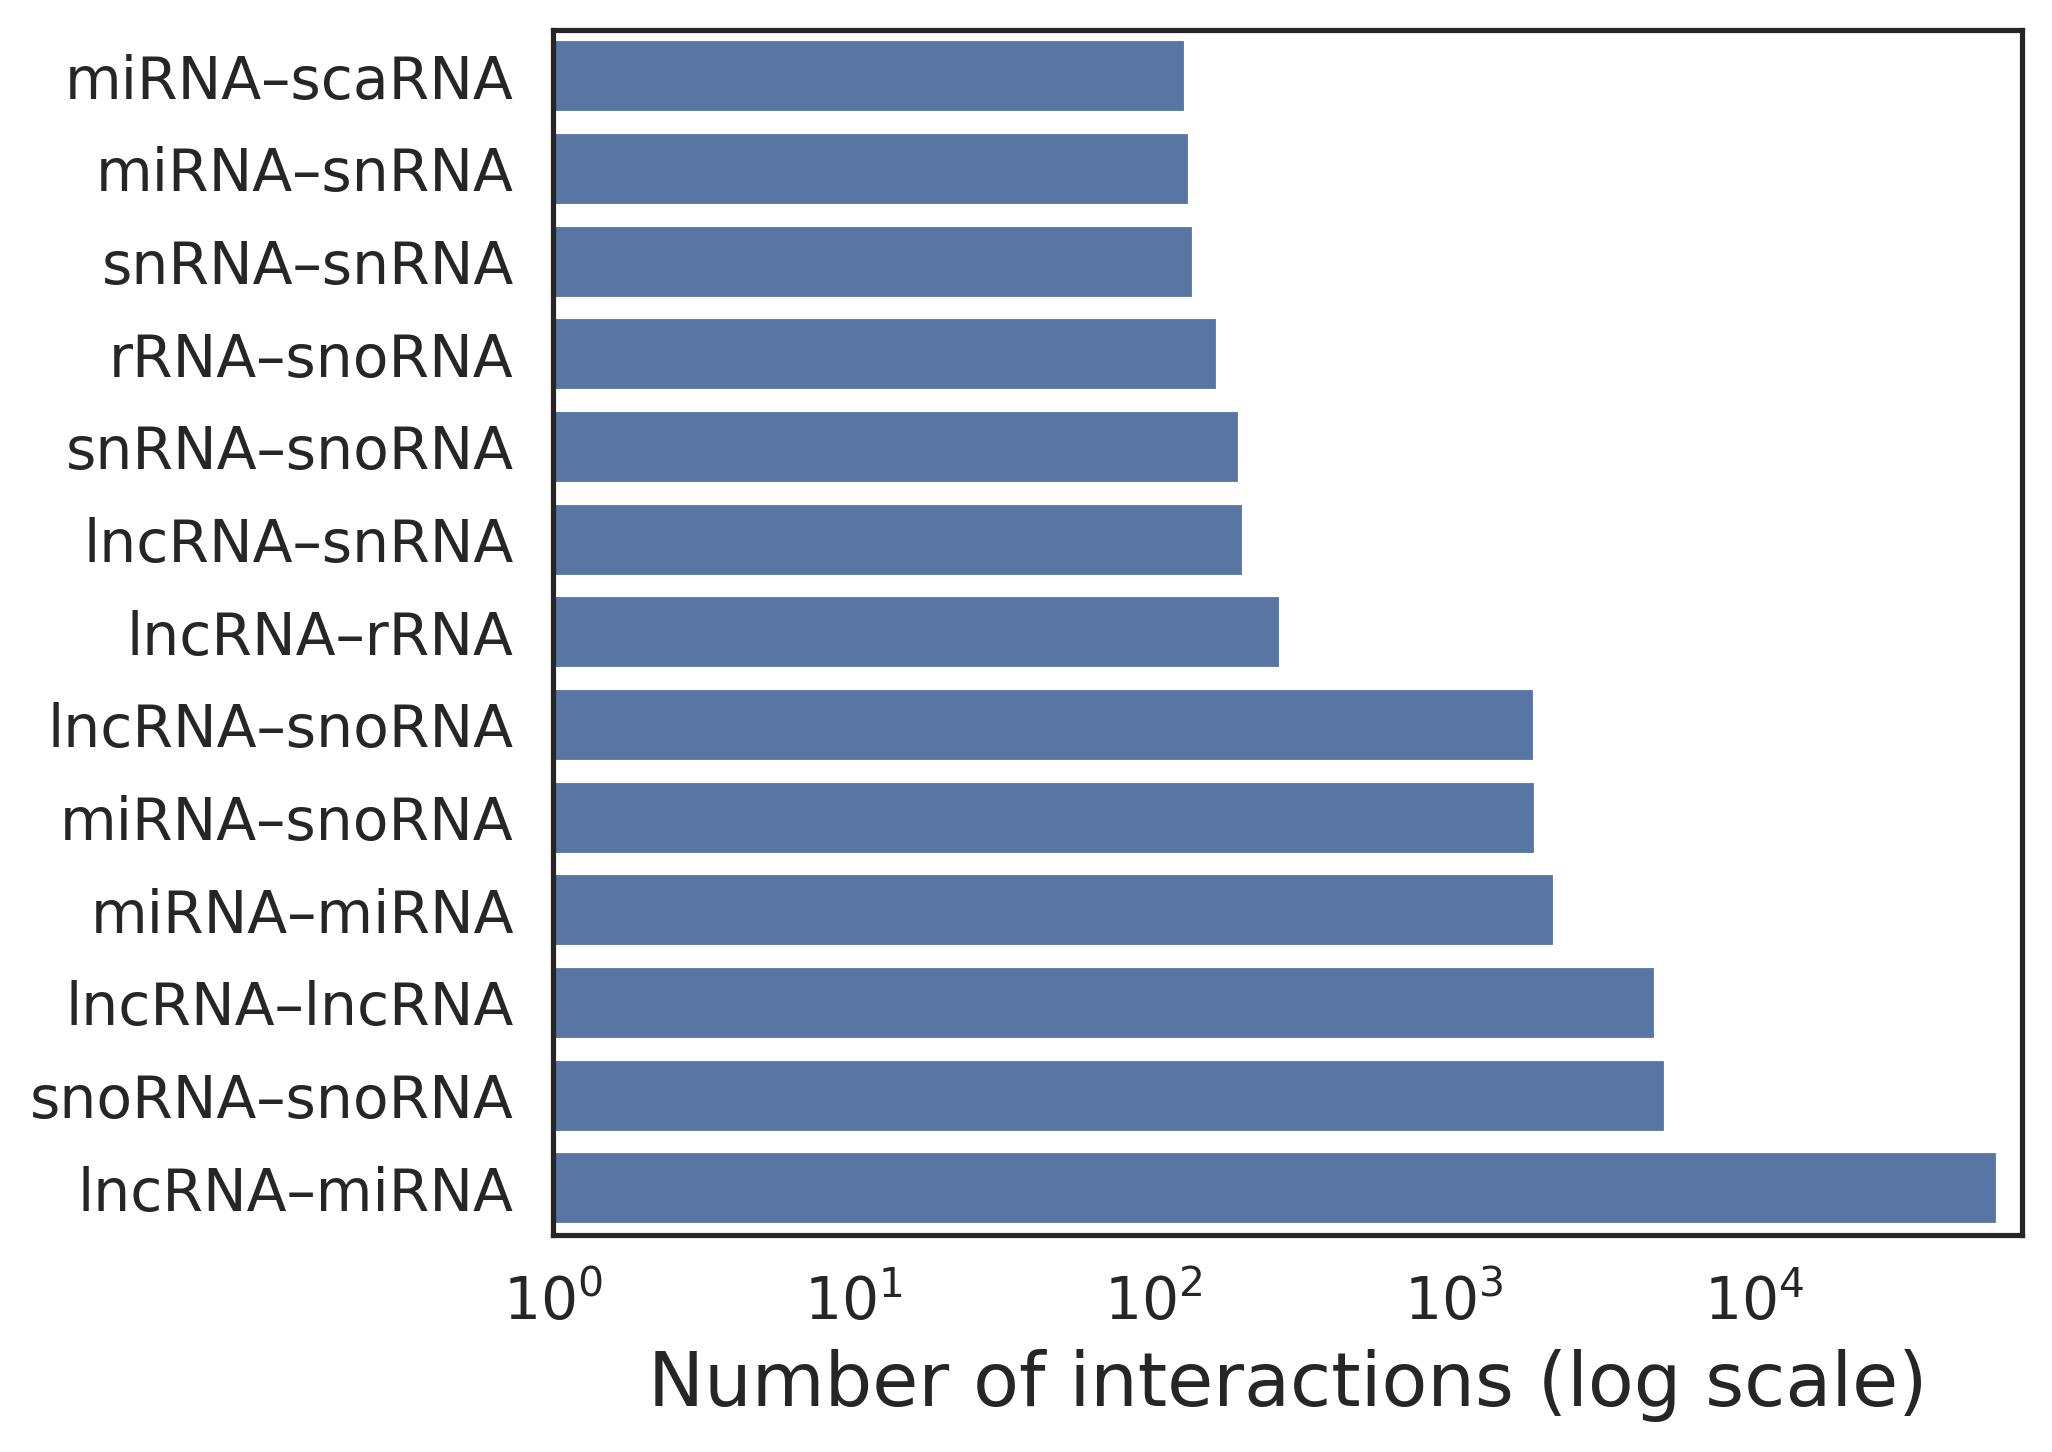

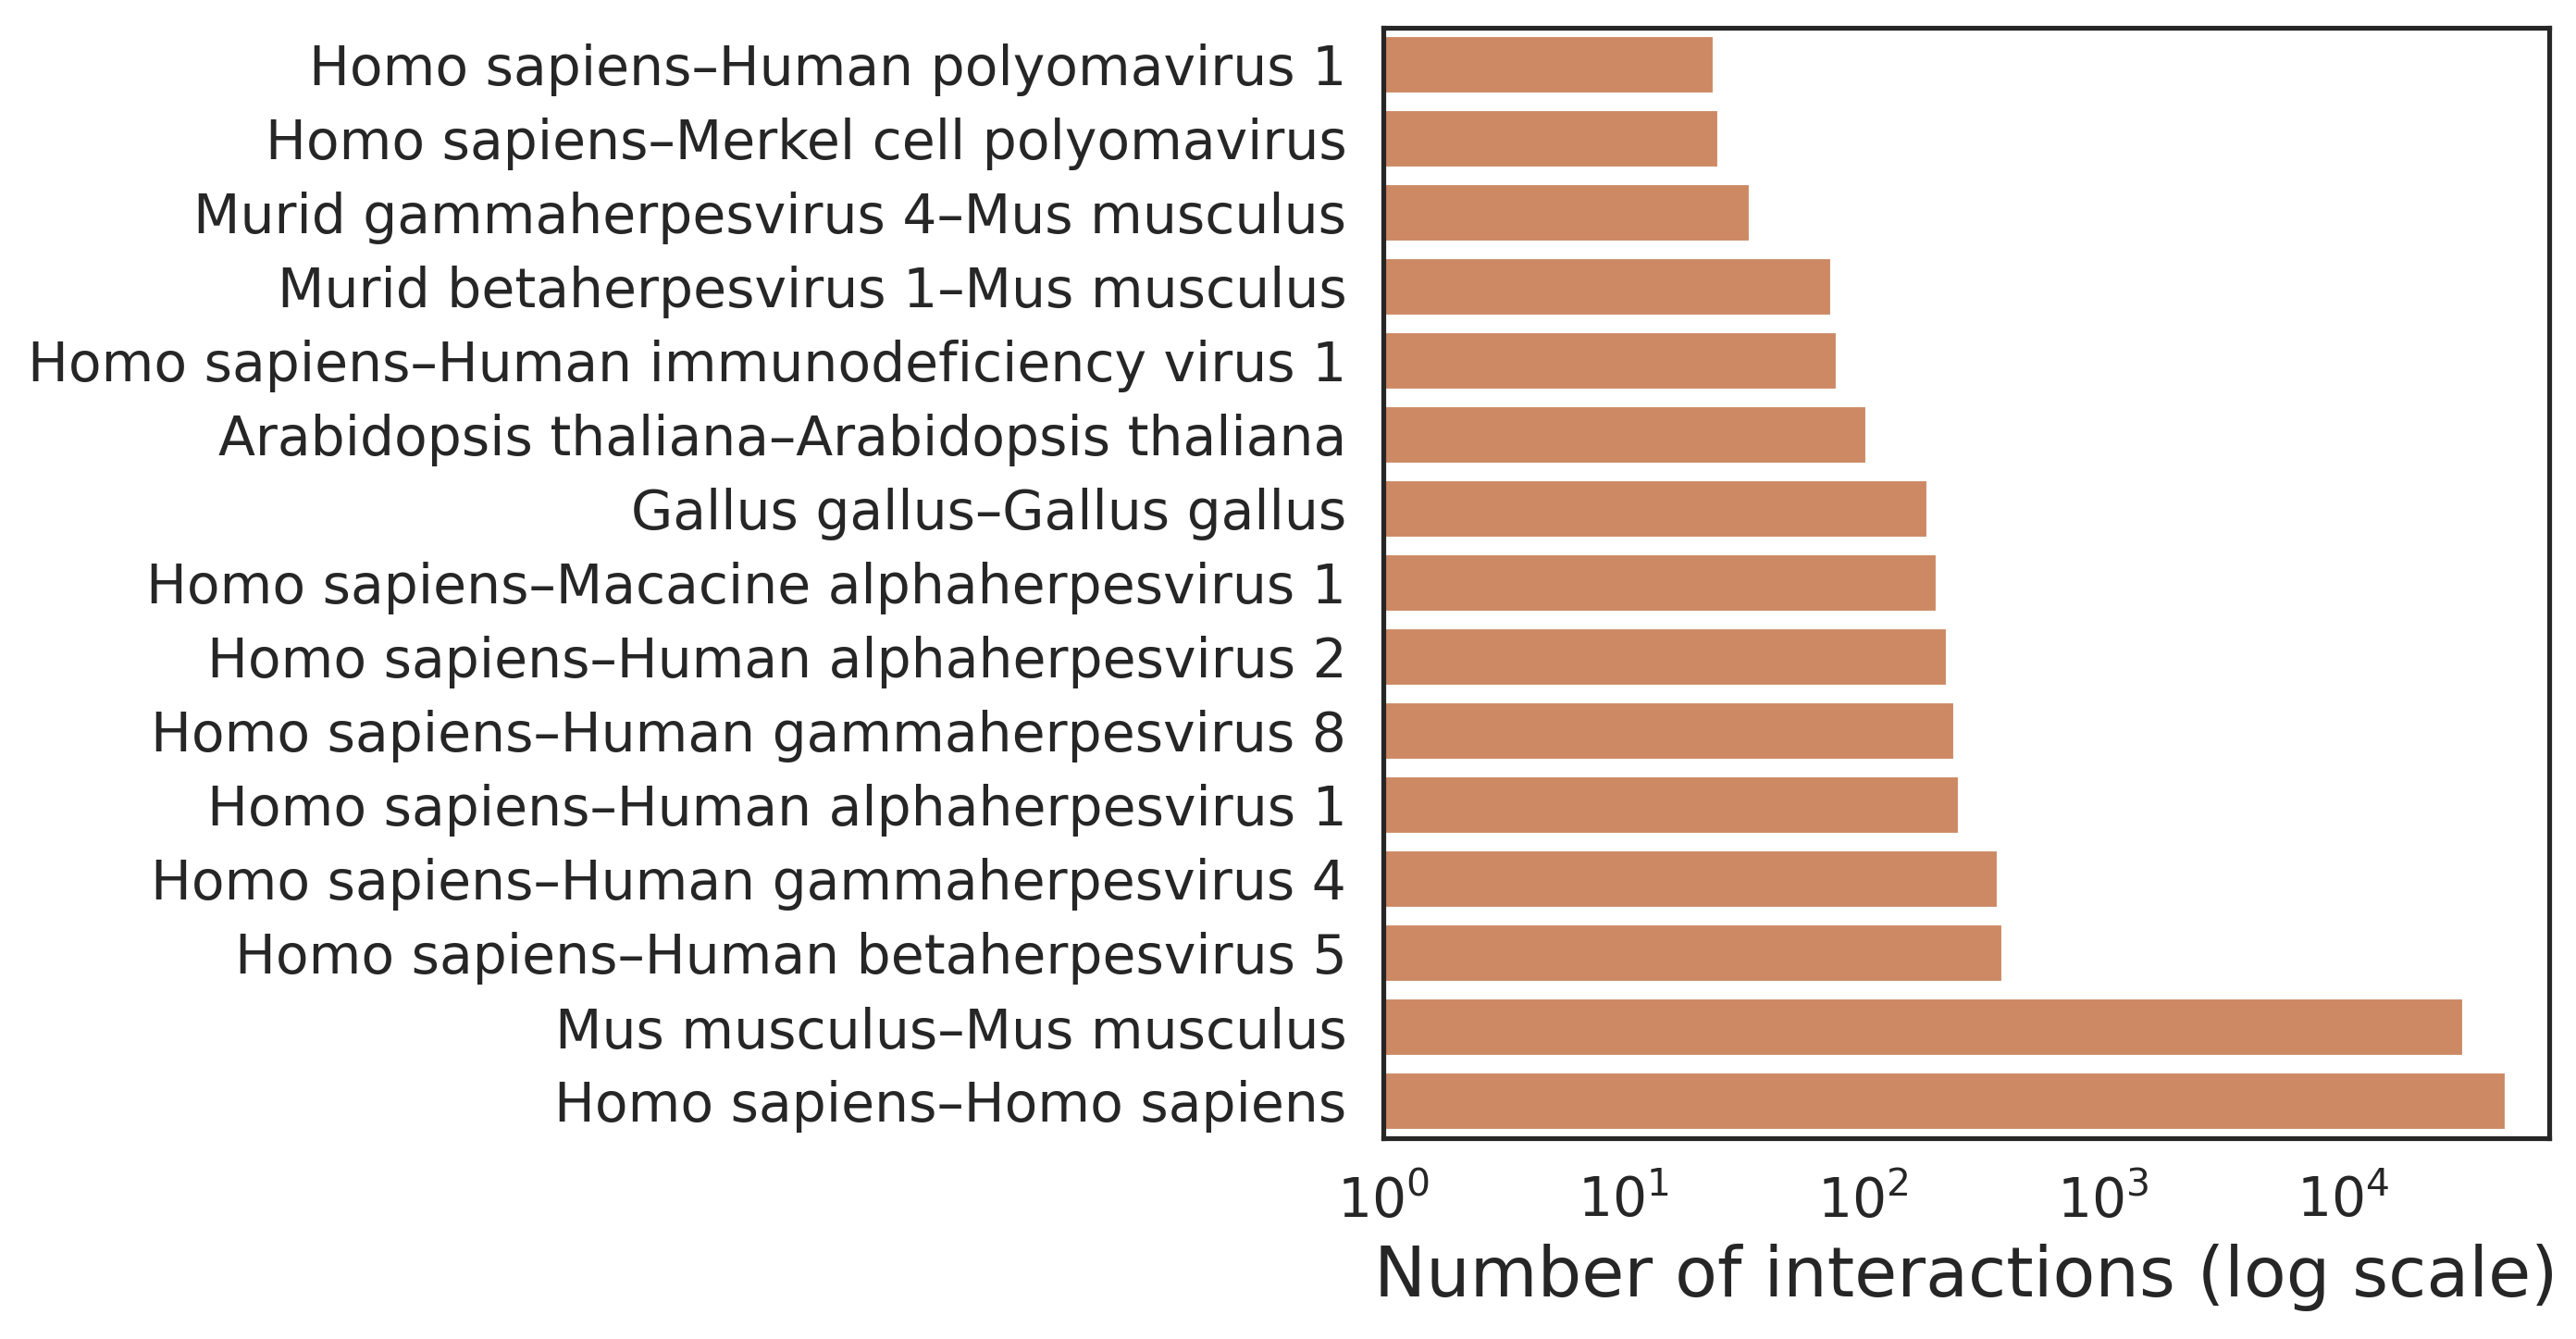

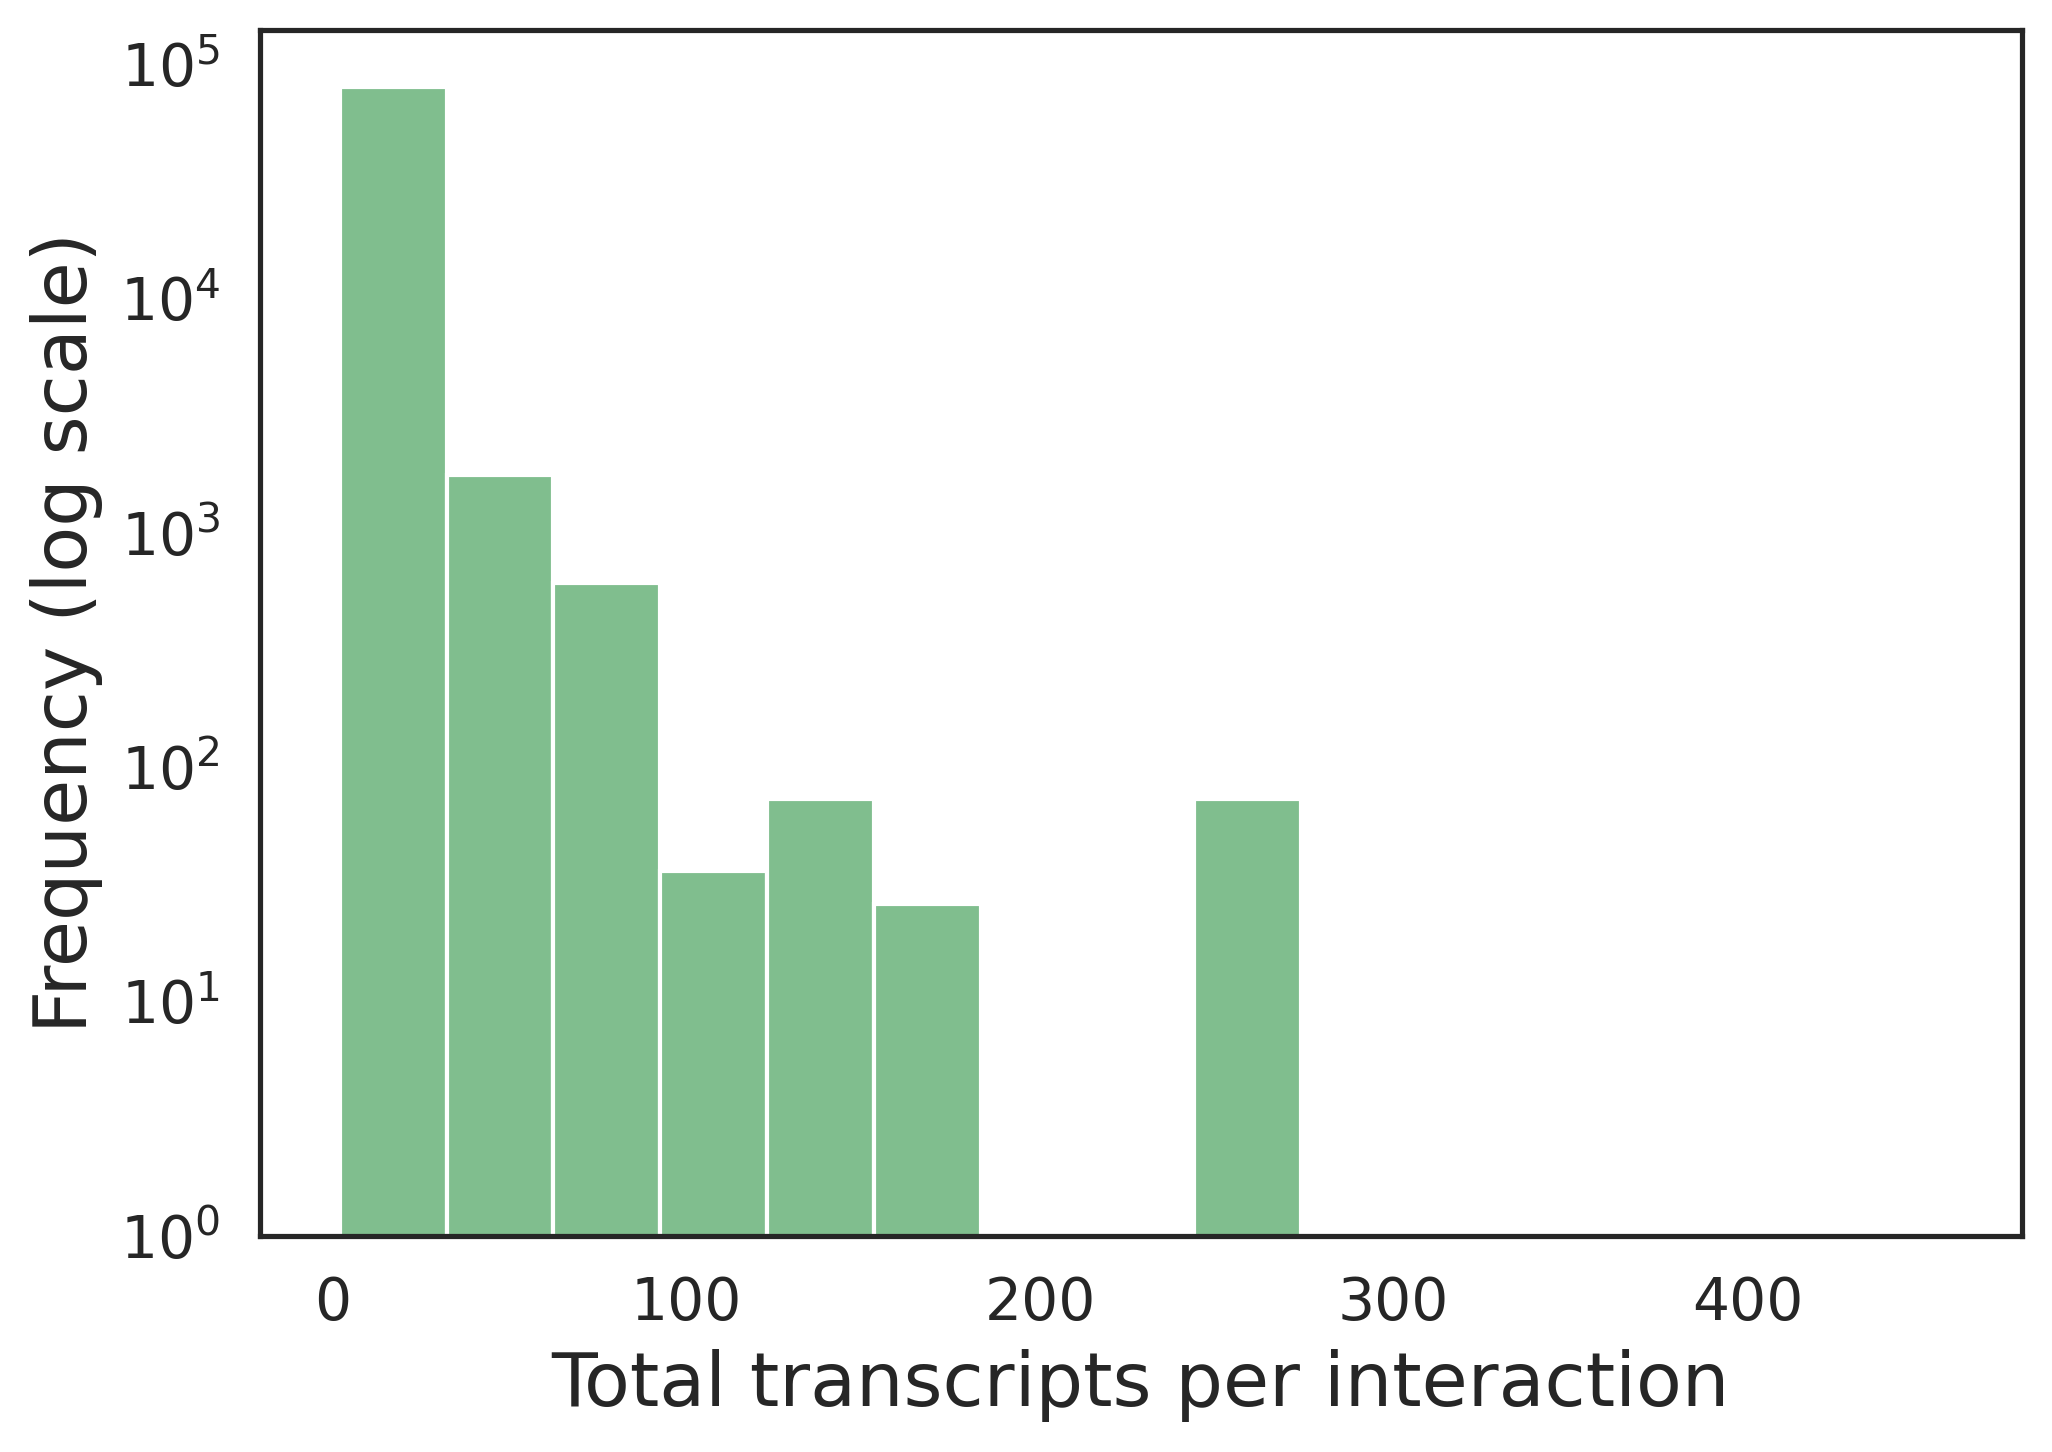

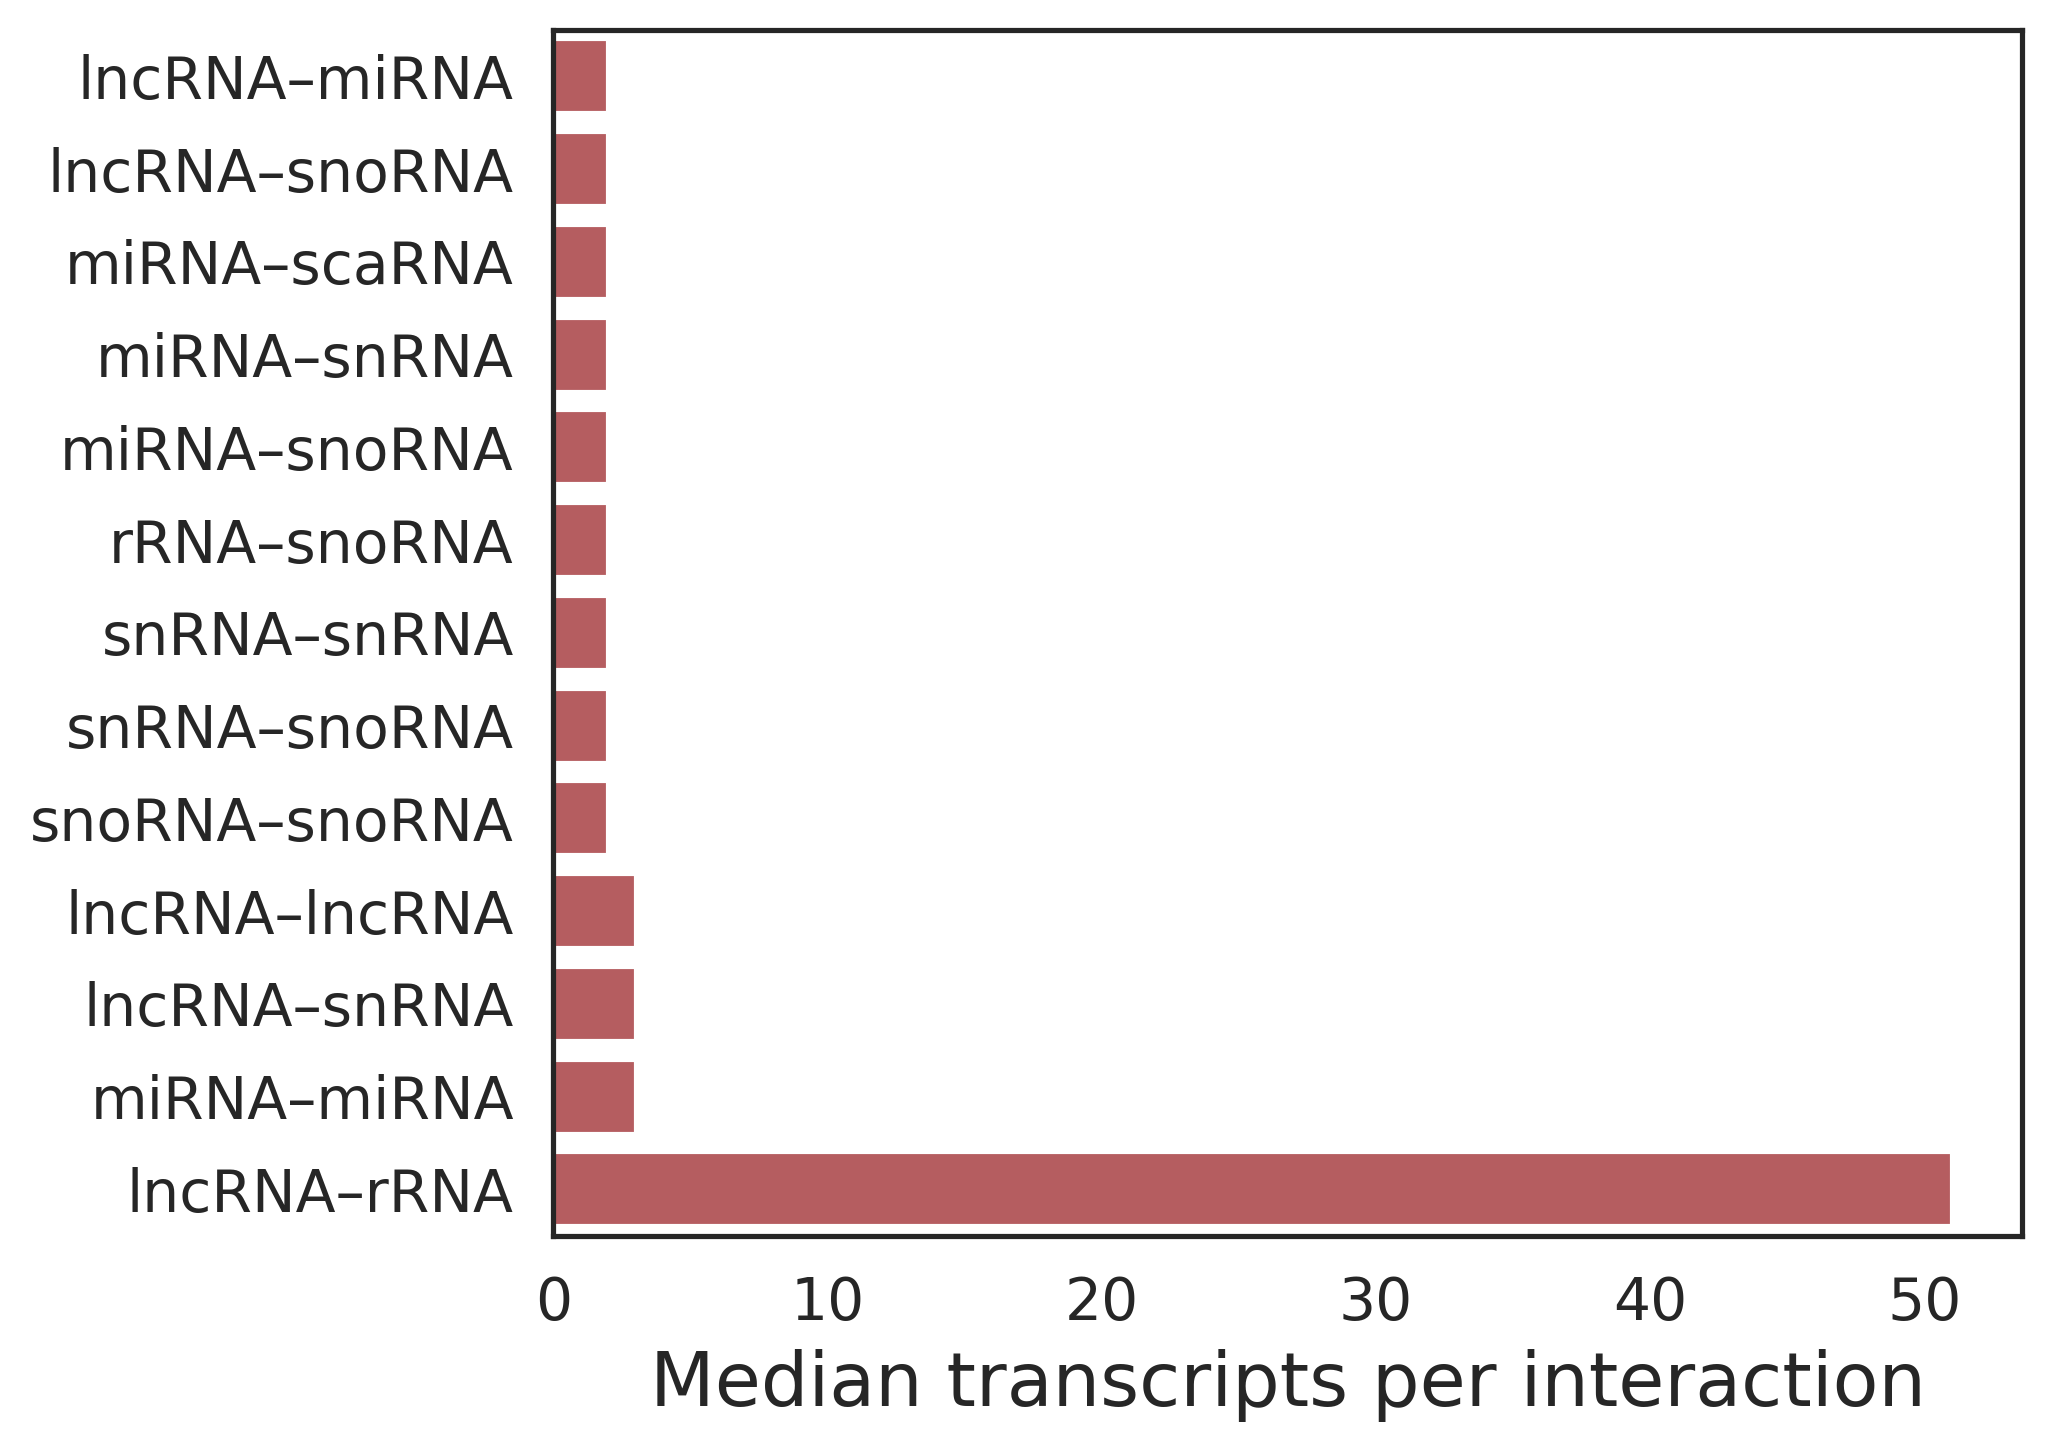

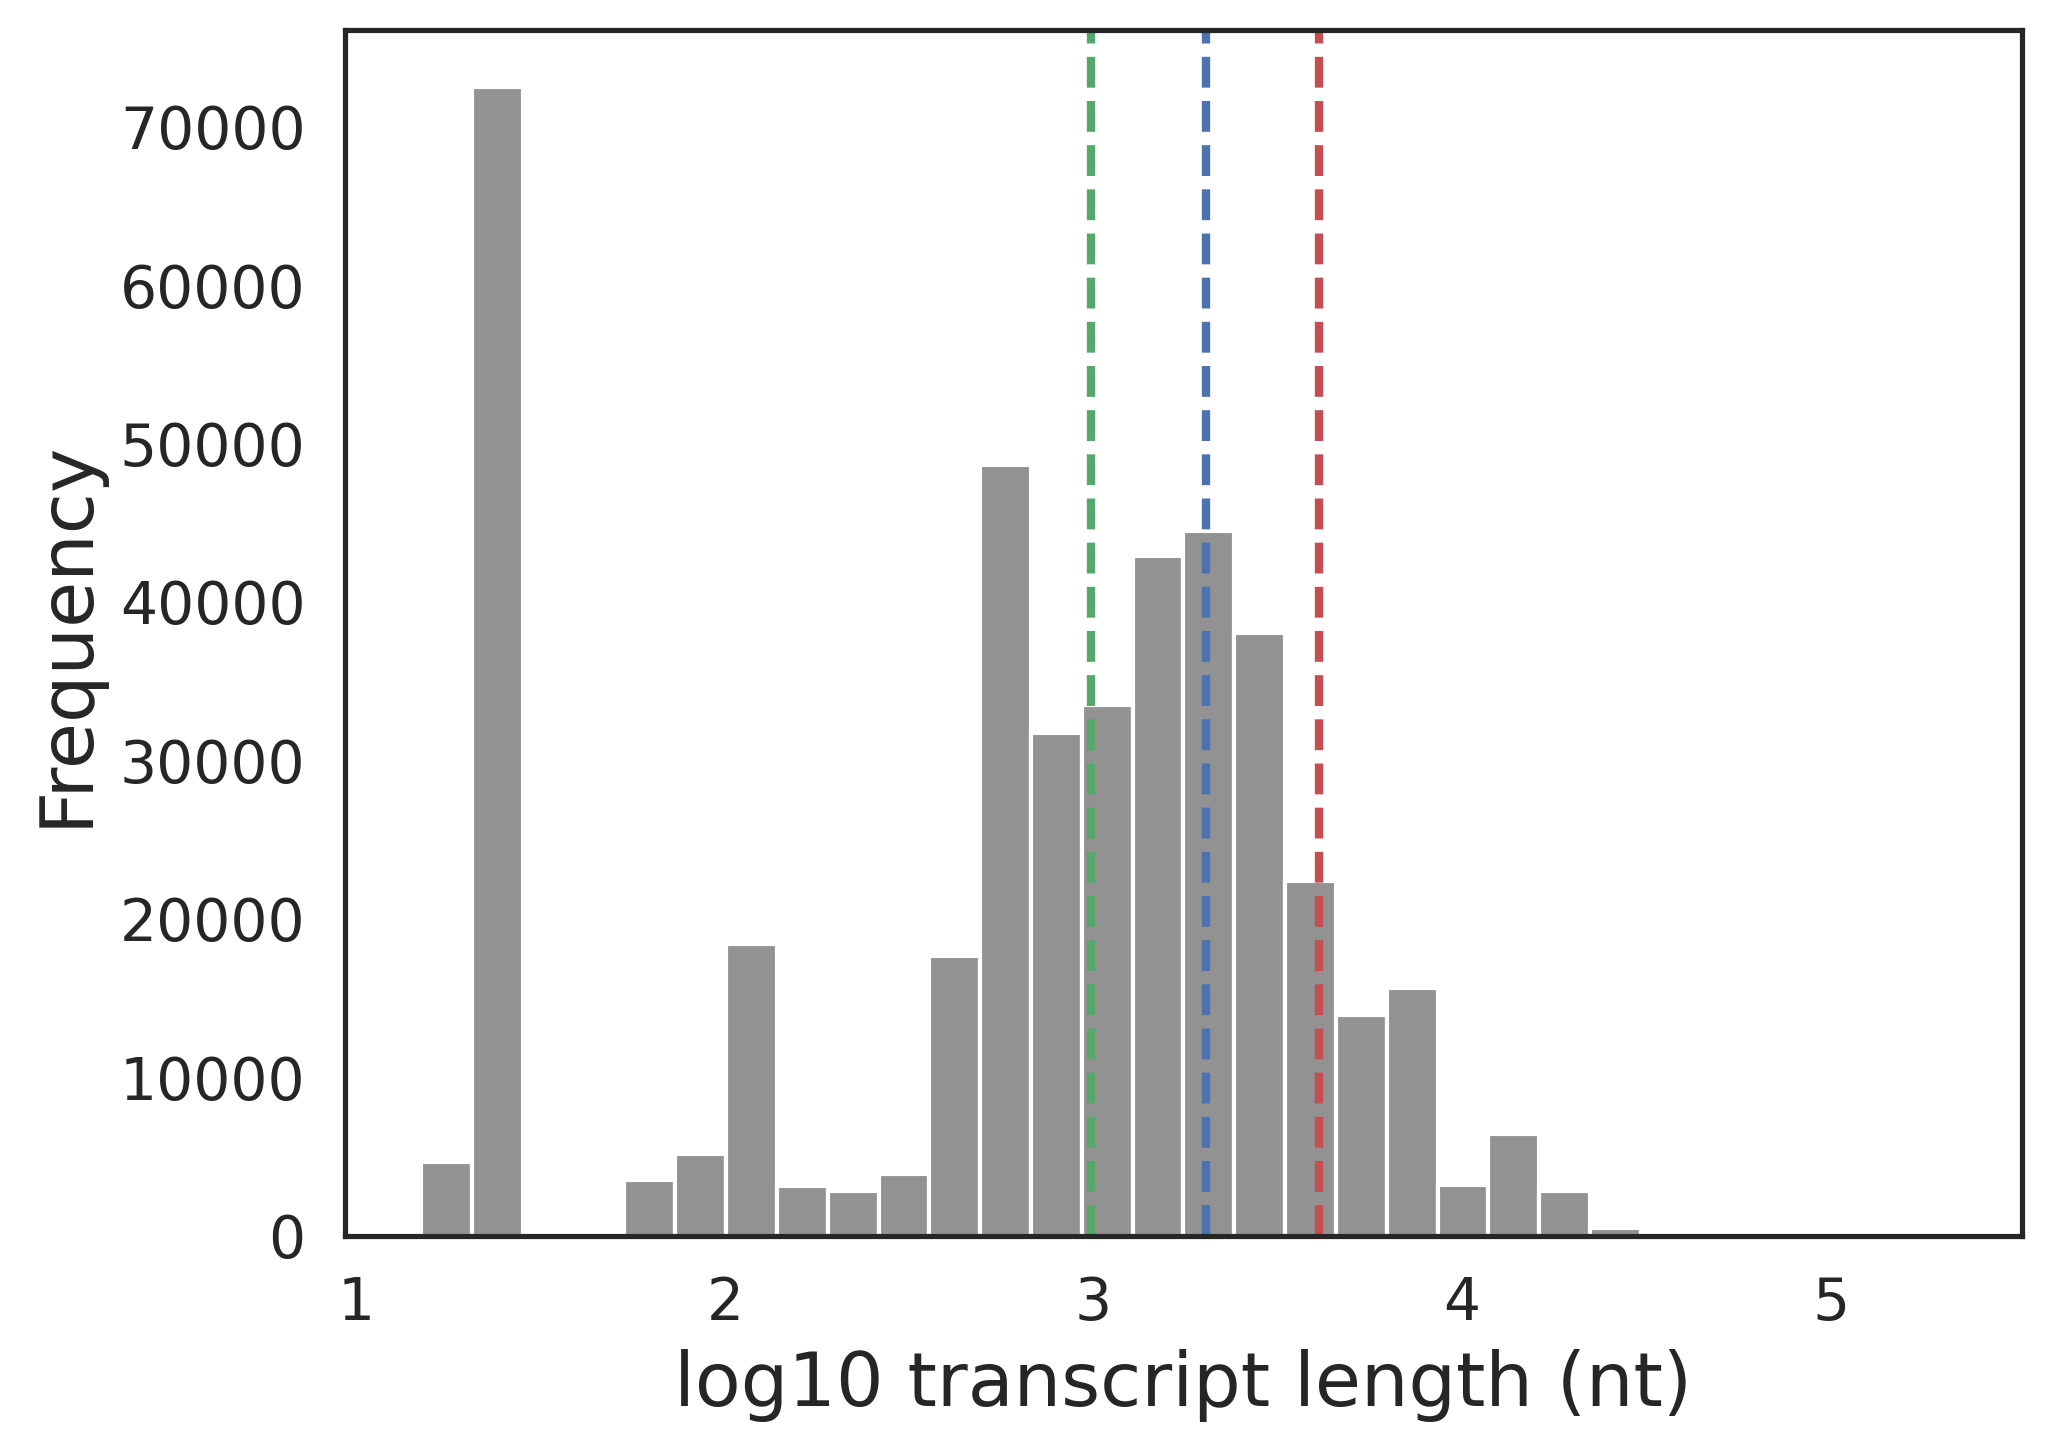

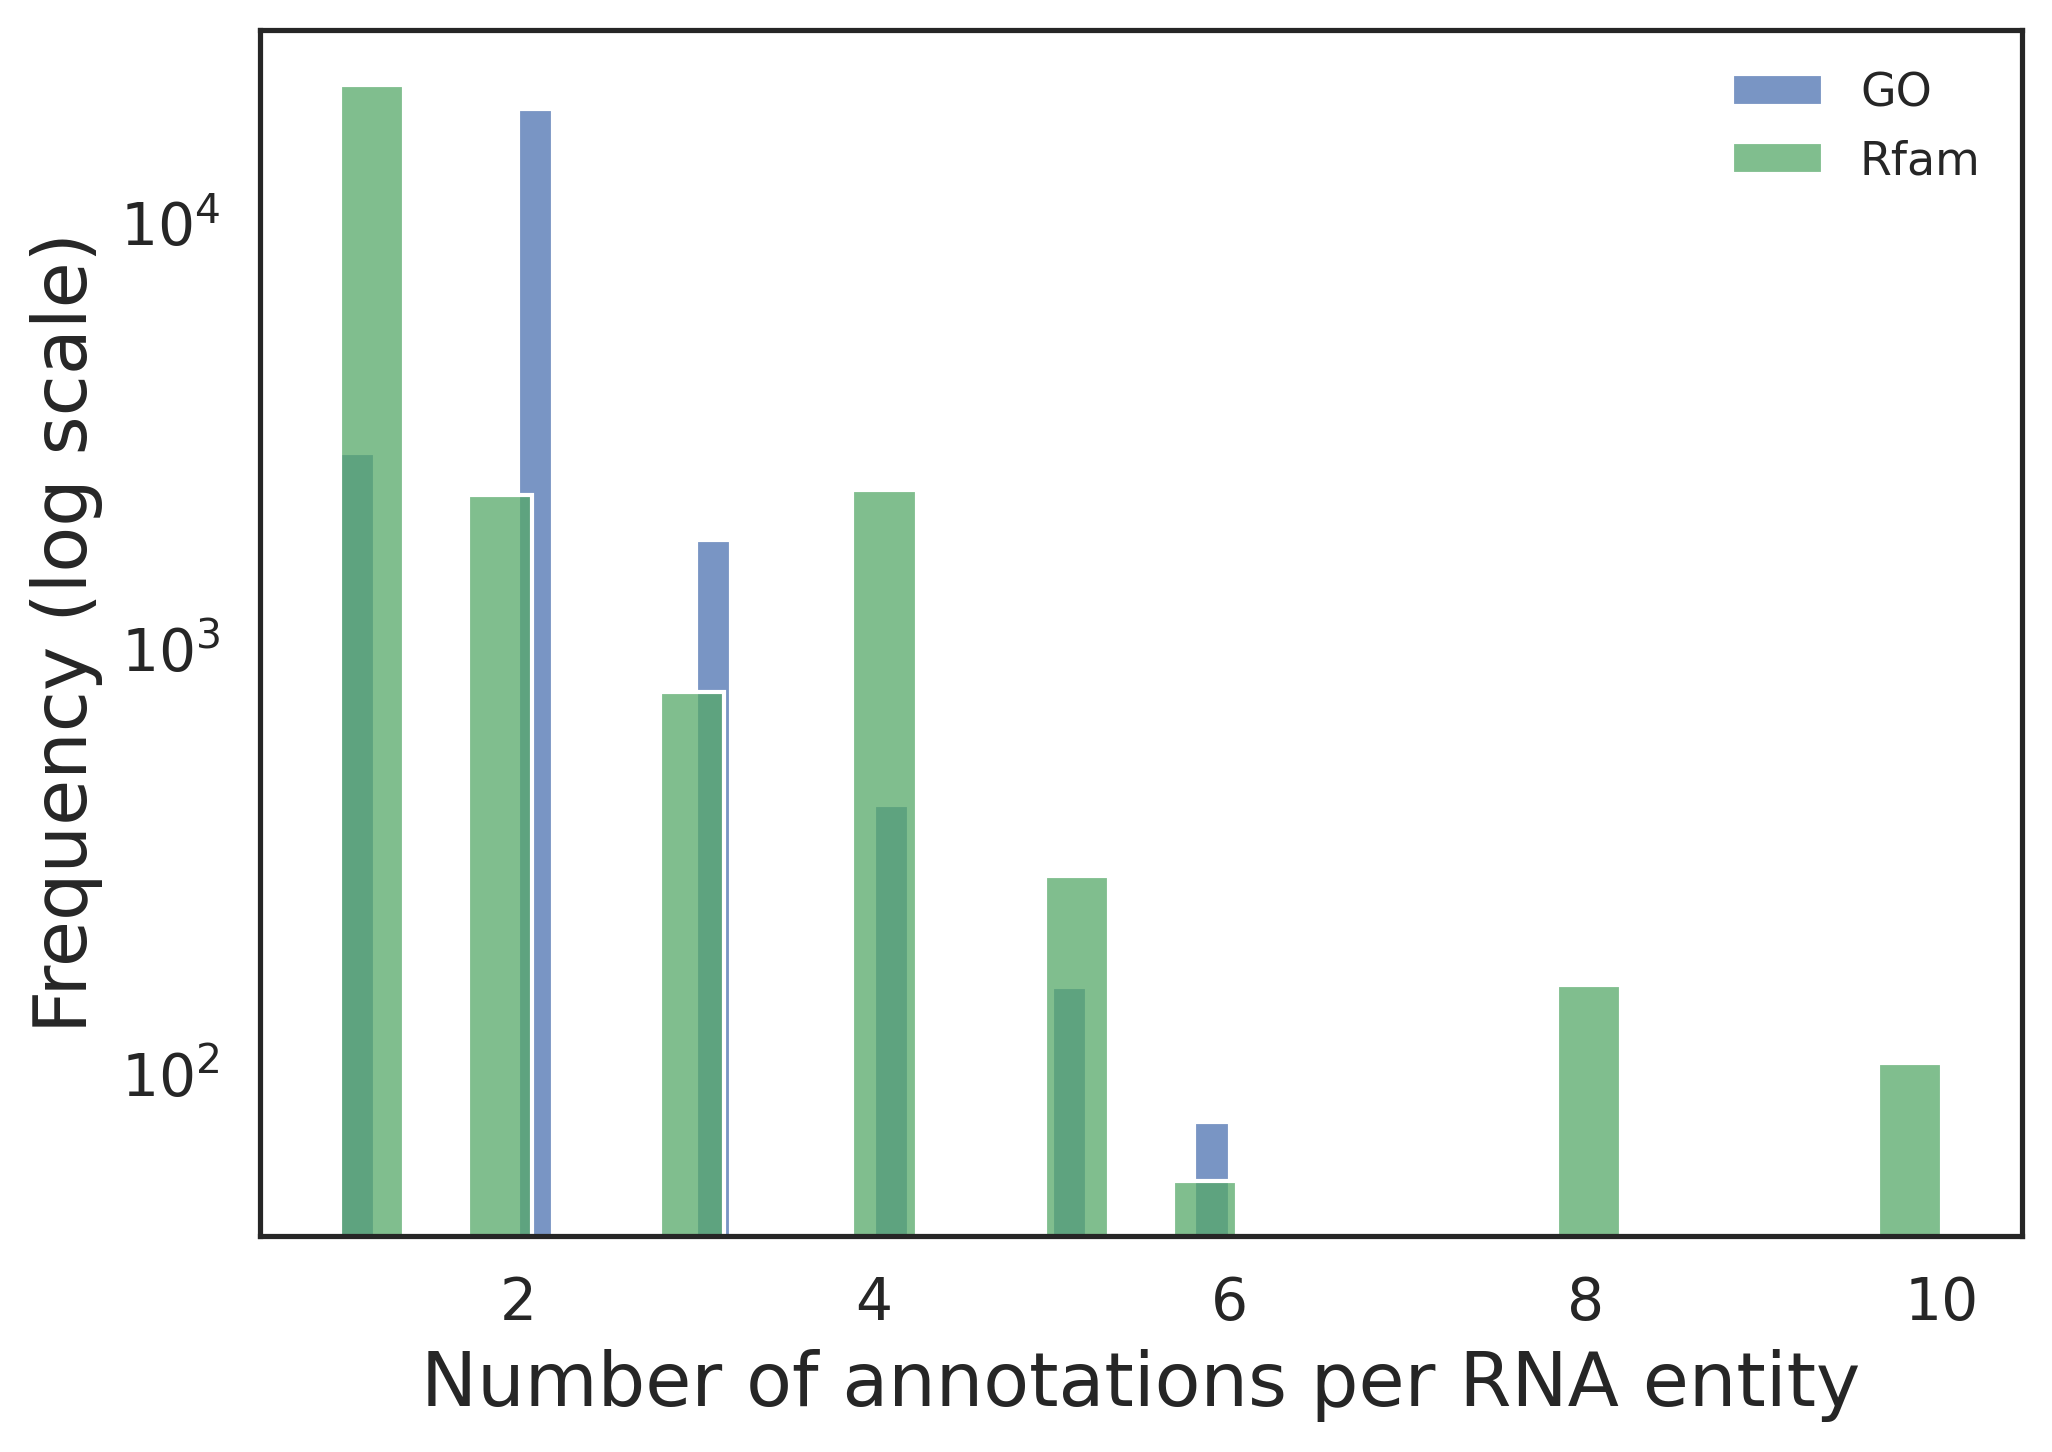

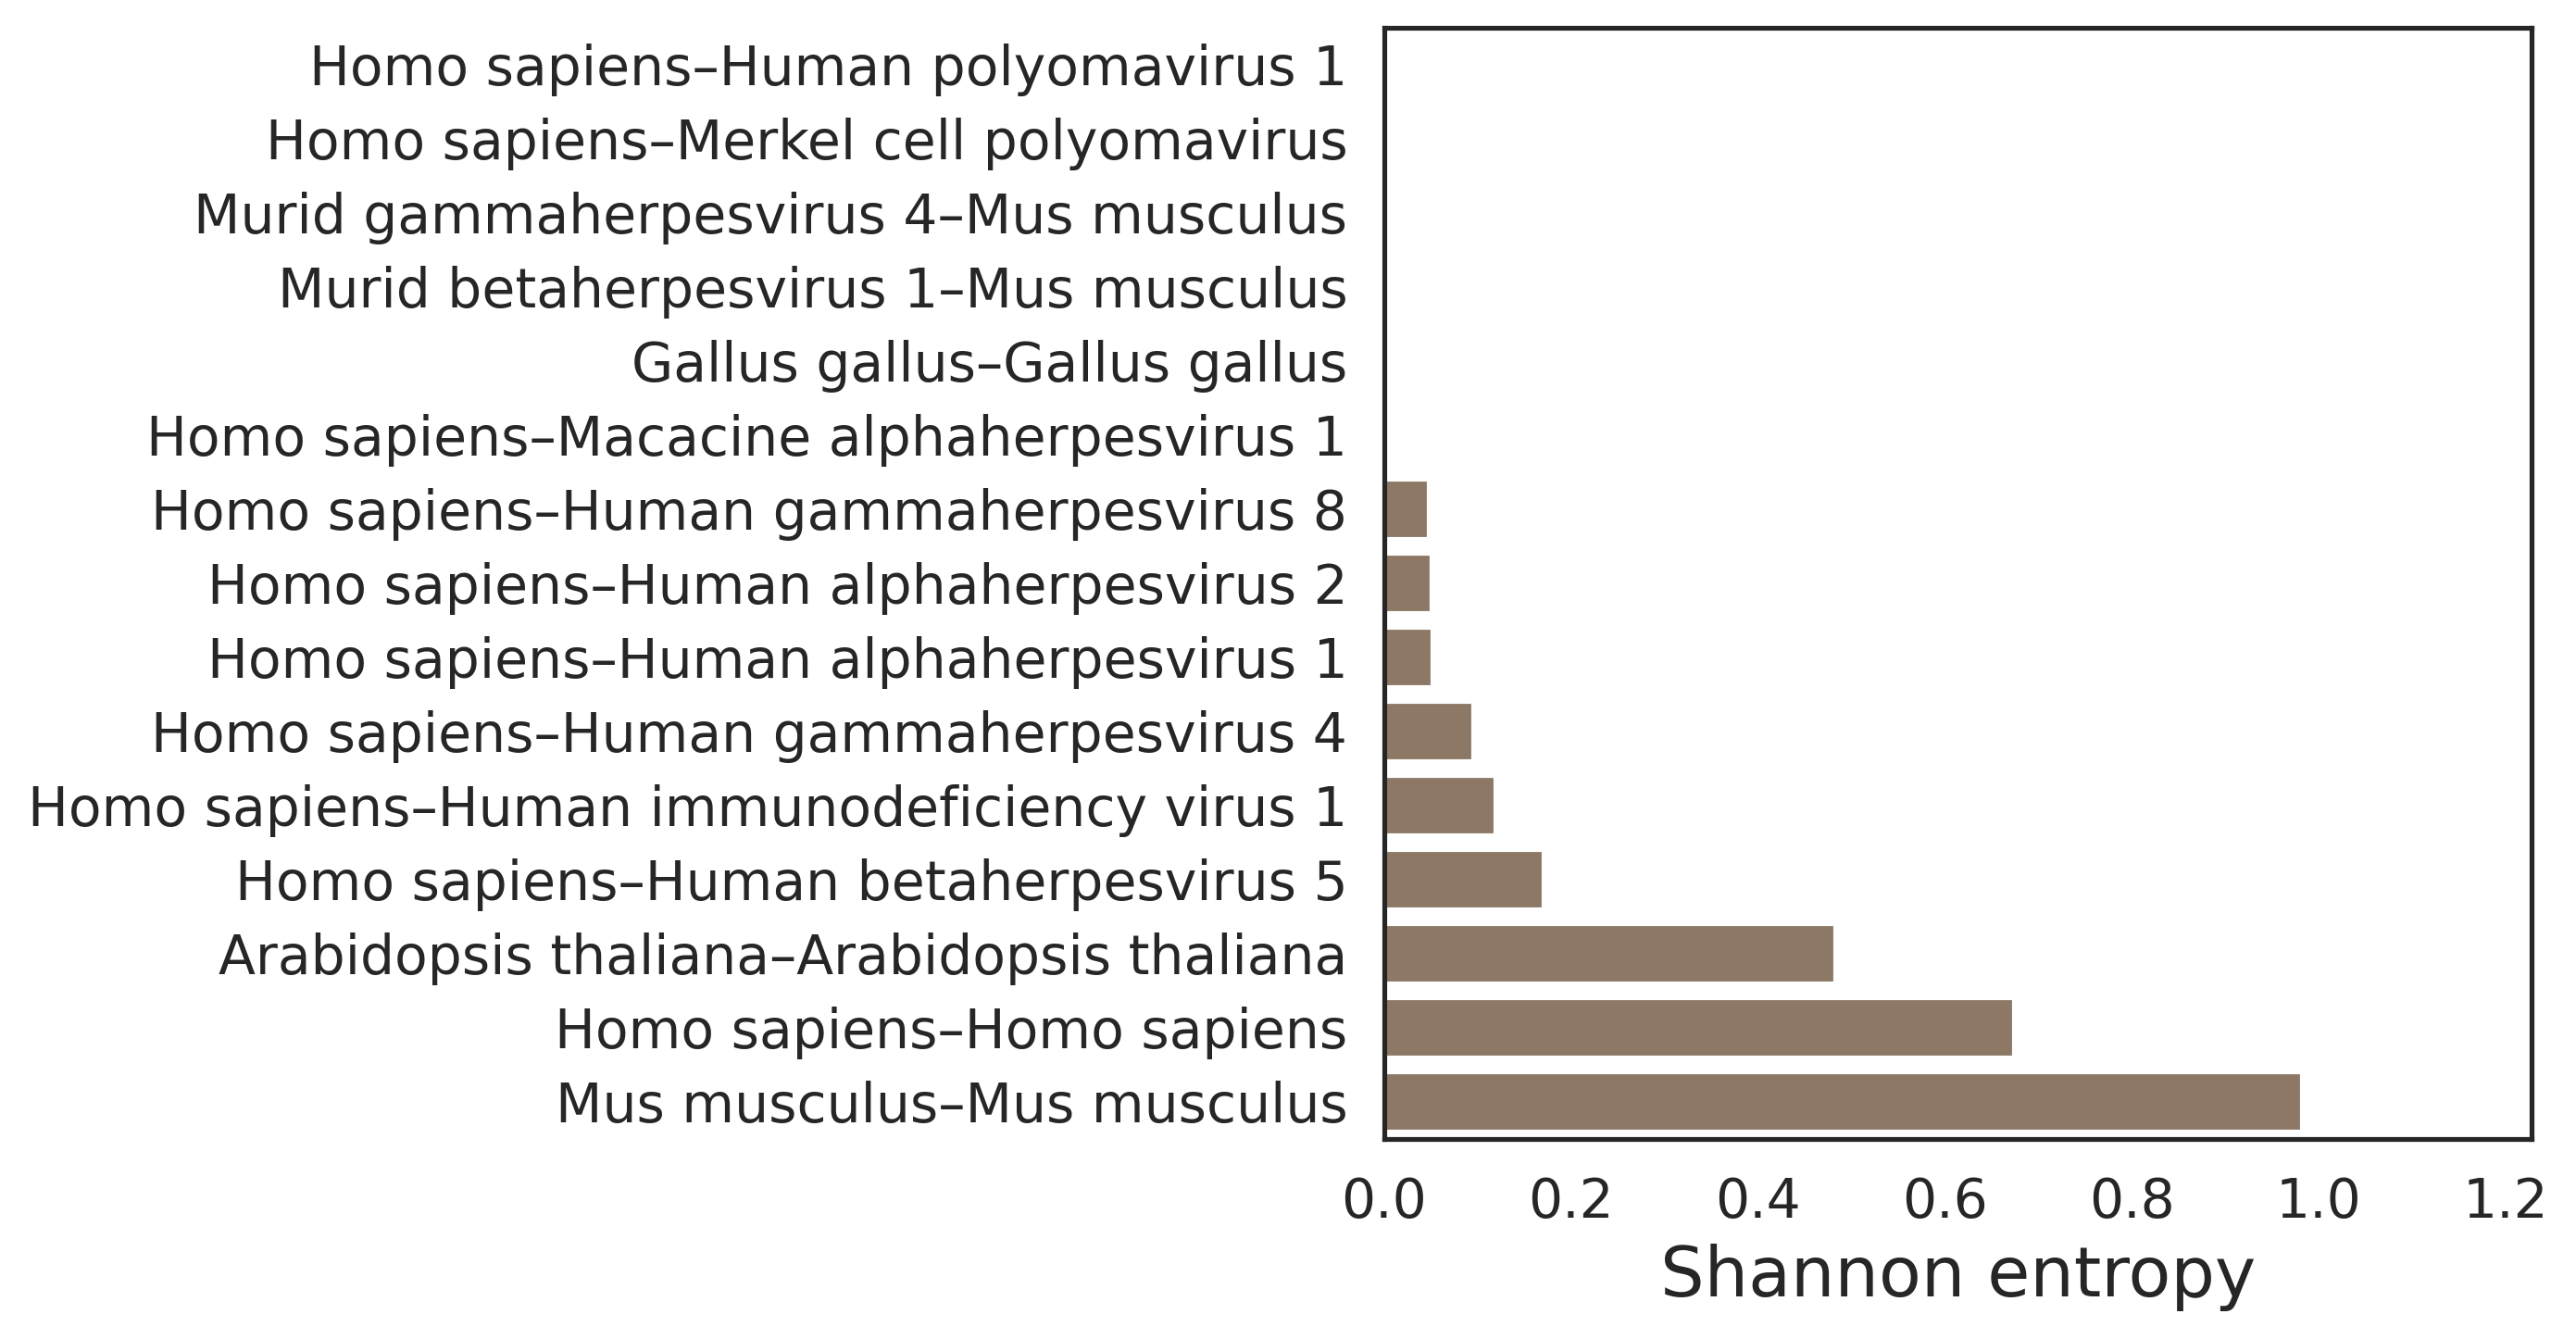

All figures saved as PDF.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy.stats import entropy

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (6,4)

print("Shape:", df.shape)
df.head()


df["type_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Category1"], x["Category2"]])),
    axis=1
)

type_pair_counts = df["type_pair_unordered"].value_counts()

type_pair_counts.head(40)


df["species_pair_unordered"] = df.apply(
    lambda x: tuple(sorted([x["Species1"], x["Species2"]])),
    axis=1
)

def count_valid_seqs(x):
    if isinstance(x, list):
        return len([s for s in x if isinstance(s, str) and len(s) > 0])
    return 0

df["n_transcripts_total"] = (
    df["seq1_list"].apply(count_valid_seqs) +
    df["seq2_list"].apply(count_valid_seqs)
)

species_pair_counts = df["species_pair_unordered"].value_counts()
species_pair_counts.head(40)



# ==========================================
# RNA Interaction Dataset – Core Landscape
# Clean, reduced, publication-ready
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
from scipy.stats import entropy

# ---------------------------
# Global style
# ---------------------------
mpl.rcParams.update({
    "figure.figsize": (7,5),
    "figure.dpi": 300,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif"
})

sns.set_style("white")

COLOR_TYPE = "#4C72B0"
COLOR_SPECIES = "#DD8452"
COLOR_TRANSCRIPT = "#55A868"
COLOR_LENGTH = "#6E6E6E"
COLOR_ANNOT = "#8172B3"
COLOR_ENTROPY = "#937860"

# ============================================================
# 1. Filtering
# ============================================================

type_counts = df["type_pair_unordered"].value_counts()
valid_types = type_counts[type_counts >= 100].index
df_f = df[df["type_pair_unordered"].isin(valid_types)].copy()

print("Final dataset size:", len(df_f))
print("Types retained:", df_f["type_pair_unordered"].nunique())
print("Species pairs retained:", df_f["species_pair_unordered"].nunique())

# ============================================================
# 2. Interaction Type Distribution (log scale)
# ============================================================

type_counts_f = df_f["type_pair_unordered"].value_counts().sort_values()

plt.figure()
sns.barplot(
    x=type_counts_f.values,
    y=[f"{a}–{b}" for a,b in type_counts_f.index],
    color=COLOR_TYPE
)
plt.xscale("log")
plt.xlim(1, type_counts_f.values.max() * 1.2)
plt.xlabel("Number of interactions (log scale)")
plt.tight_layout()
plt.savefig("Fig1_type_distribution.pdf")
plt.show()
plt.close()

# ============================================================
# 3. Species Interaction Landscape (Top 15)
# ============================================================

species_counts_f = (
    df_f["species_pair_unordered"]
    .value_counts()
    .head(15)
    .sort_values()
)

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=species_counts_f.values,
    y=[f"{a}–{b}" for a,b in species_counts_f.index],
    color=COLOR_SPECIES,
    ax=ax
)

ax.set_xscale("log")

# add proper right margin buffer
max_val = species_counts_f.values.max()
ax.set_xlim(1, max_val * 1.5)

ax.set_xlabel("Number of interactions (log scale)")

# manually adjust margins (prevents right cutoff)
fig.subplots_adjust(left=0.35, right=0.95, top=0.95, bottom=0.15)

plt.savefig("Fig2_species_landscape.pdf", bbox_inches="tight")
plt.show()
plt.close()


# ============================================================
# 4. Transcript Multiplicity
# ============================================================

plt.figure()
sns.histplot(
    df_f["n_transcripts_total"],
    bins=15,
    color=COLOR_TRANSCRIPT
)
plt.yscale("log")
plt.ylim(bottom=1)
plt.xlabel("Total transcripts per interaction")
plt.ylabel("Frequency (log scale)")
plt.tight_layout()
plt.savefig("Fig3_transcript_multiplicity.pdf")
plt.show()
plt.close()

# Median transcript multiplicity per type
transcript_median = (
    df_f.groupby("type_pair_unordered")["n_transcripts_total"]
    .median()
    .sort_values()
)

plt.figure()
sns.barplot(
    x=transcript_median.values,
    y=[f"{a}–{b}" for a,b in transcript_median.index],
    color="#C44E52"
)
plt.xlabel("Median transcripts per interaction")
plt.tight_layout()
plt.savefig("Fig3b_transcript_median_per_type.pdf")
plt.show()
plt.close()

# ============================================================
# 5. Transcript Length Distribution (log-scale)
# ============================================================

all_lengths = []

for lst in df_f["seq1_list"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

for lst in df_f["seq2_list"]:
    if isinstance(lst, list):
        all_lengths.extend([len(s) for s in lst if isinstance(s, str)])

all_lengths = np.array(all_lengths)
all_lengths = all_lengths[all_lengths > 0]

mean_len = np.mean(all_lengths)
median_len = np.median(all_lengths)

plt.figure()
sns.histplot(
    np.log10(all_lengths),
    bins=30,
    color=COLOR_LENGTH
)

plt.axvline(np.log10(4096), color="#C44E52", linestyle="--", linewidth=2)
plt.axvline(np.log10(mean_len), color="#4C72B0", linestyle="--", linewidth=2)
plt.axvline(np.log10(median_len), color="#55A868", linestyle="--", linewidth=2)

plt.xlabel("log10 transcript length (nt)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig("Fig4_transcript_length_log_distribution.pdf")
plt.show()
plt.close()

# ============================================================
# 6. Functional Annotation Landscape (Entity-Level)
# ============================================================

def count_valid_annotations(x):
    if isinstance(x, list):
        return len([v for v in x if pd.notna(v)])
    return 0

df_f["n_GO1"] = df_f["GO1"].apply(count_valid_annotations)
df_f["n_GO2"] = df_f["GO2"].apply(count_valid_annotations)
df_f["n_Rfam1"] = df_f["Rfam1"].apply(count_valid_annotations)
df_f["n_Rfam2"] = df_f["Rfam2"].apply(count_valid_annotations)

all_GO = pd.concat([df_f["n_GO1"], df_f["n_GO2"]])
all_Rfam = pd.concat([df_f["n_Rfam1"], df_f["n_Rfam2"]])

# Annotation depth (log scale)
plt.figure()
sns.histplot(all_GO[all_GO > 0], bins=25, color="#4C72B0", label="GO")
sns.histplot(all_Rfam[all_Rfam > 0], bins=25, color="#55A868", label="Rfam")
plt.yscale("log")
plt.xlabel("Number of annotations per RNA entity")
plt.ylabel("Frequency (log scale)")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("Fig6_annotation_depth.pdf")
plt.show()
plt.close()

# ============================================================
# 7. Interaction-Type Diversity per Species
# ============================================================

entropy_values = []
species_list = species_counts_f.index

for sp in species_list:
    subset = df_f[df_f["species_pair_unordered"] == sp]
    counts = subset["type_pair_unordered"].value_counts()
    entropy_values.append(entropy(counts))

entropy_series = pd.Series(
    entropy_values,
    index=[f"{a}–{b}" for a,b in species_list]
).sort_values()

fig, ax = plt.subplots(figsize=(7,5))

sns.barplot(
    x=entropy_series.values,
    y=entropy_series.index,
    color=COLOR_ENTROPY,
    ax=ax
)

max_val = entropy_series.max()
ax.set_xlim(0, max_val * 1.25)  # more right padding
ax.set_xlabel("Shannon entropy")
ax.set_ylabel("")

# manual margin control (critical for NatComm-style large fonts)
fig.subplots_adjust(left=0.38, right=0.97, top=0.95, bottom=0.15)

plt.savefig("Fig7_species_entropy.pdf", bbox_inches="tight")
plt.show()
plt.close()


print("All figures saved as PDF.")


In [3]:
df.keys()

Index(['RNAInterID', 'Interactor1.Symbol', 'Category1', 'Species1',
       'Interactor2.Symbol', 'Category2', 'Species2', 'Raw_ID1', 'Raw_ID2',
       'score', 'strong', 'weak', 'predict', 'Raw_ID1_list', 'Raw_ID2_list',
       'Species1_TaxID', 'Species2_TaxID', 'Category1_std', 'Category2_std',
       'Raw_ID1_key', 'Raw_ID2_key', 'key1', 'key2', 'seq1_list', 'GO1',
       'Rfam1', 'ID_buckets1', 'seq2_list', 'GO2', 'Rfam2', 'ID_buckets2',
       'type_pair_unordered', 'species_pair_unordered', 'n_transcripts_total'],
      dtype='object')

In [4]:
# ============================================================
# ncRNA ENTITY EXTRACTION (Entity-level, not transcript-level)
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 0. Configuration
# ------------------------------------------------------------

# Adapt this list to your standardized category space
NCRNA_CATEGORIES = {
    "miRNA",
    "lncRNA",
    "snoRNA",
    "snRNA",
    "piRNA",
    "circRNA",
    "rRNA",
    "tRNA",
    "scaRNA",
    "antisense",
    "ncRNA"
}

# ------------------------------------------------------------
# 1. Canonical entity key
# ------------------------------------------------------------

def make_entity_key(symbol, category, species, raw_id_list):
    raw_ids = tuple(sorted(raw_id_list)) if isinstance(raw_id_list, list) else tuple()
    return (symbol, category, species, raw_ids)

# ------------------------------------------------------------
# 2. Extract ncRNA entities from both interactors
# ------------------------------------------------------------

entities = []

for side in [1, 2]:

    symbol_col = f"Interactor{side}.Symbol"
    category_col = f"Category{side}_std"
    species_col = f"Species{side}"
    raw_id_col = f"Raw_ID{side}_list"
    seq_col = f"seq{side}_list"
    go_col = f"GO{side}"
    rfam_col = f"Rfam{side}"
    bucket_col = f"ID_buckets{side}"

    df_side = df[
        df[category_col].isin(NCRNA_CATEGORIES)
    ][[
        symbol_col,
        category_col,
        species_col,
        raw_id_col,
        seq_col,
        go_col,
        rfam_col,
        bucket_col
    ]].copy()

    df_side.columns = [
        "symbol",
        "category",
        "species",
        "raw_ids",
        "seq_list",
        "GO",
        "Rfam",
        "ID_buckets"
    ]

    entities.append(df_side)

df_ncrna = pd.concat(entities, ignore_index=True)

print("Total ncRNA entries (with duplicates):", len(df_ncrna))

# ------------------------------------------------------------
# 3. Deduplicate entities using canonical key
# ------------------------------------------------------------

df_ncrna["entity_key"] = df_ncrna.apply(
    lambda x: make_entity_key(
        x["symbol"],
        x["category"],
        x["species"],
        x["raw_ids"]
    ),
    axis=1
)

df_ncrna_unique = (
    df_ncrna
    .drop_duplicates(subset="entity_key")
    .reset_index(drop=True)
)

print("Unique ncRNA entities:", len(df_ncrna_unique))

# ------------------------------------------------------------
# 4. Transcript-level statistics per entity
# ------------------------------------------------------------

def valid_sequences(lst):
    if isinstance(lst, list):
        return [s for s in lst if isinstance(s, str) and len(s) > 0]
    return []

def count_annotations(lst):
    if isinstance(lst, list):
        return len([v for v in lst if pd.notna(v)])
    return 0

df_ncrna_unique["n_transcripts"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: len(valid_sequences(x)))
)

df_ncrna_unique["mean_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.mean([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

df_ncrna_unique["median_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.median([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

df_ncrna_unique["max_transcript_length"] = (
    df_ncrna_unique["seq_list"]
    .apply(lambda x: np.max([len(s) for s in valid_sequences(x)])
           if len(valid_sequences(x)) > 0 else np.nan)
)

# ------------------------------------------------------------
# 5. Functional annotation depth
# ------------------------------------------------------------

df_ncrna_unique["n_GO"] = df_ncrna_unique["GO"].apply(count_annotations)
df_ncrna_unique["n_Rfam"] = df_ncrna_unique["Rfam"].apply(count_annotations)

# ------------------------------------------------------------
# 6. Basic dataset diagnostics
# ------------------------------------------------------------

print("\nCategory distribution:")
print(df_ncrna_unique["category"].value_counts())

print("\nSpecies distribution (top 10):")
print(df_ncrna_unique["species"].value_counts().head(10))

print("\nTranscript count summary:")
print(df_ncrna_unique["n_transcripts"].describe())

print("\nTranscript length summary:")
print(df_ncrna_unique["mean_transcript_length"].describe())

# ------------------------------------------------------------
# 7. Save final dataset
# ------------------------------------------------------------

df_ncrna_unique.to_pickle("ncrna_entities_final.pkl")

print("\nSaved: ncrna_entities_final.pkl")

Total ncRNA entries (with duplicates): 164307
Unique ncRNA entities: 11928

Category distribution:
category
lncRNA    6111
miRNA     4662
snoRNA     839
snRNA      182
rRNA        90
scaRNA      22
tRNA        18
ncRNA        4
Name: count, dtype: int64

Species distribution (top 10):
species
Homo sapiens                7765
Mus musculus                3630
Arabidopsis thaliana         133
Gallus gallus                128
Human gammaherpesvirus 4      43
Rattus norvegicus             28
Human alphaherpesvirus 1      26
Human betaherpesvirus 5       25
Human gammaherpesvirus 8      25
Human alphaherpesvirus 2      22
Name: count, dtype: int64

Transcript count summary:
count    11928.000000
mean         2.539906
std          8.976699
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max        454.000000
Name: n_transcripts, dtype: float64

Transcript length summary:
count    11928.000000
mean       967.975375
std       1970.191815
min         15.00

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import pandas as pd

# -----------------------------
# Global plotting style
# -----------------------------
mpl.rcParams.update({
    "figure.figsize": (7,5),
    "figure.dpi": 300,
    "axes.labelsize": 18,
    "axes.titlesize": 20,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial"]
})
sns.set_style("white")
PASTEL_COLOR = "#A6CEE3"

# -----------------------------
# Bin function
# -----------------------------
def transcript_bin(n):
    if n == 1:
        return "1"
    elif n == 2:
        return "2"
    elif 3 <= n <= 5:
        return "3–5"
    elif 6 <= n <= 10:
        return "6–10"
    else:
        return ">10"

bin_order = ["1", "2", "3–5", "6–10", ">10"]

# -----------------------------
# Step 1 — count valid sequences only
# -----------------------------
df_step1 = df_ncrna_unique.copy()
df_step1["seq_list_valid"] = df_step1["seq_list"].apply(
    lambda x: [s for s in x if isinstance(s, str)] if isinstance(x, list) else []
)
df_step1["n_transcripts_orig"] = df_step1["seq_list_valid"].apply(len)
df_step1["transcript_bin_orig"] = df_step1["n_transcripts_orig"].apply(transcript_bin)

bin_counts_step1 = df_step1["transcript_bin_orig"].value_counts().reindex(bin_order, fill_value=0)
bin_counts_step1.name = "count"
print("\nStep 1 — Original counts:\n", bin_counts_step1)

# Step 2 — filter long sequences from valid sequences
MAX_TRANSCRIPT_LEN = 5000
df_step2 = df_step1.copy()

# Filter sequences
df_step2["seq_list_filtered"] = df_step2["seq_list_valid"].apply(lambda x: [s for s in x if len(s) <= MAX_TRANSCRIPT_LEN])

# Count only sequences that survived filtering
df_step2["n_transcripts_filtered"] = df_step2["seq_list_filtered"].apply(len)

# Only bin entities with at least 1 sequence
df_step2["transcript_bin_filtered"] = df_step2["n_transcripts_filtered"].apply(lambda n: transcript_bin(n) if n > 0 else "0")

# Optional: remove 0 for plotting
bin_order_step2 = ["1", "2", "3–5", "6–10", ">10"]
bin_counts_step2 = df_step2[df_step2["n_transcripts_filtered"] > 0]["transcript_bin_filtered"].value_counts().reindex(bin_order_step2, fill_value=0)
bin_counts_step2.name = "count"
print("\nStep 2 — Counts afterfilter for seq len:\n", bin_counts_step2)

# -----------------------------
# Step 3 — keep entities with >=2 transcripts
# -----------------------------
df_step3 = df_step2[df_step2["n_transcripts_filtered"] >= 2].copy()
df_step3["transcript_bin_multi"] = df_step3["n_transcripts_filtered"].apply(transcript_bin)

bin_counts_step3 = df_step3["transcript_bin_multi"].value_counts().reindex(bin_order, fill_value=0)
bin_counts_step3 = bin_counts_step3.drop("1")  # Bin 1 removed
bin_counts_step3.name = "count"
print("\nStep 3 — Counts after keeping entities with ≥2 transcripts:\n", bin_counts_step3)


Step 1 — Original counts:
 transcript_bin_orig
1       8634
2       1350
3–5     1278
6–10     284
>10      382
Name: count, dtype: int64

Step 2 — Counts afterfilter for seq len:
 transcript_bin_filtered
1       8536
2       1334
3–5     1258
6–10     279
>10      363
Name: count, dtype: int64

Step 3 — Counts after keeping entities with ≥2 transcripts:
 transcript_bin_multi
2       1334
3–5     1258
6–10     279
>10      363
Name: count, dtype: int64


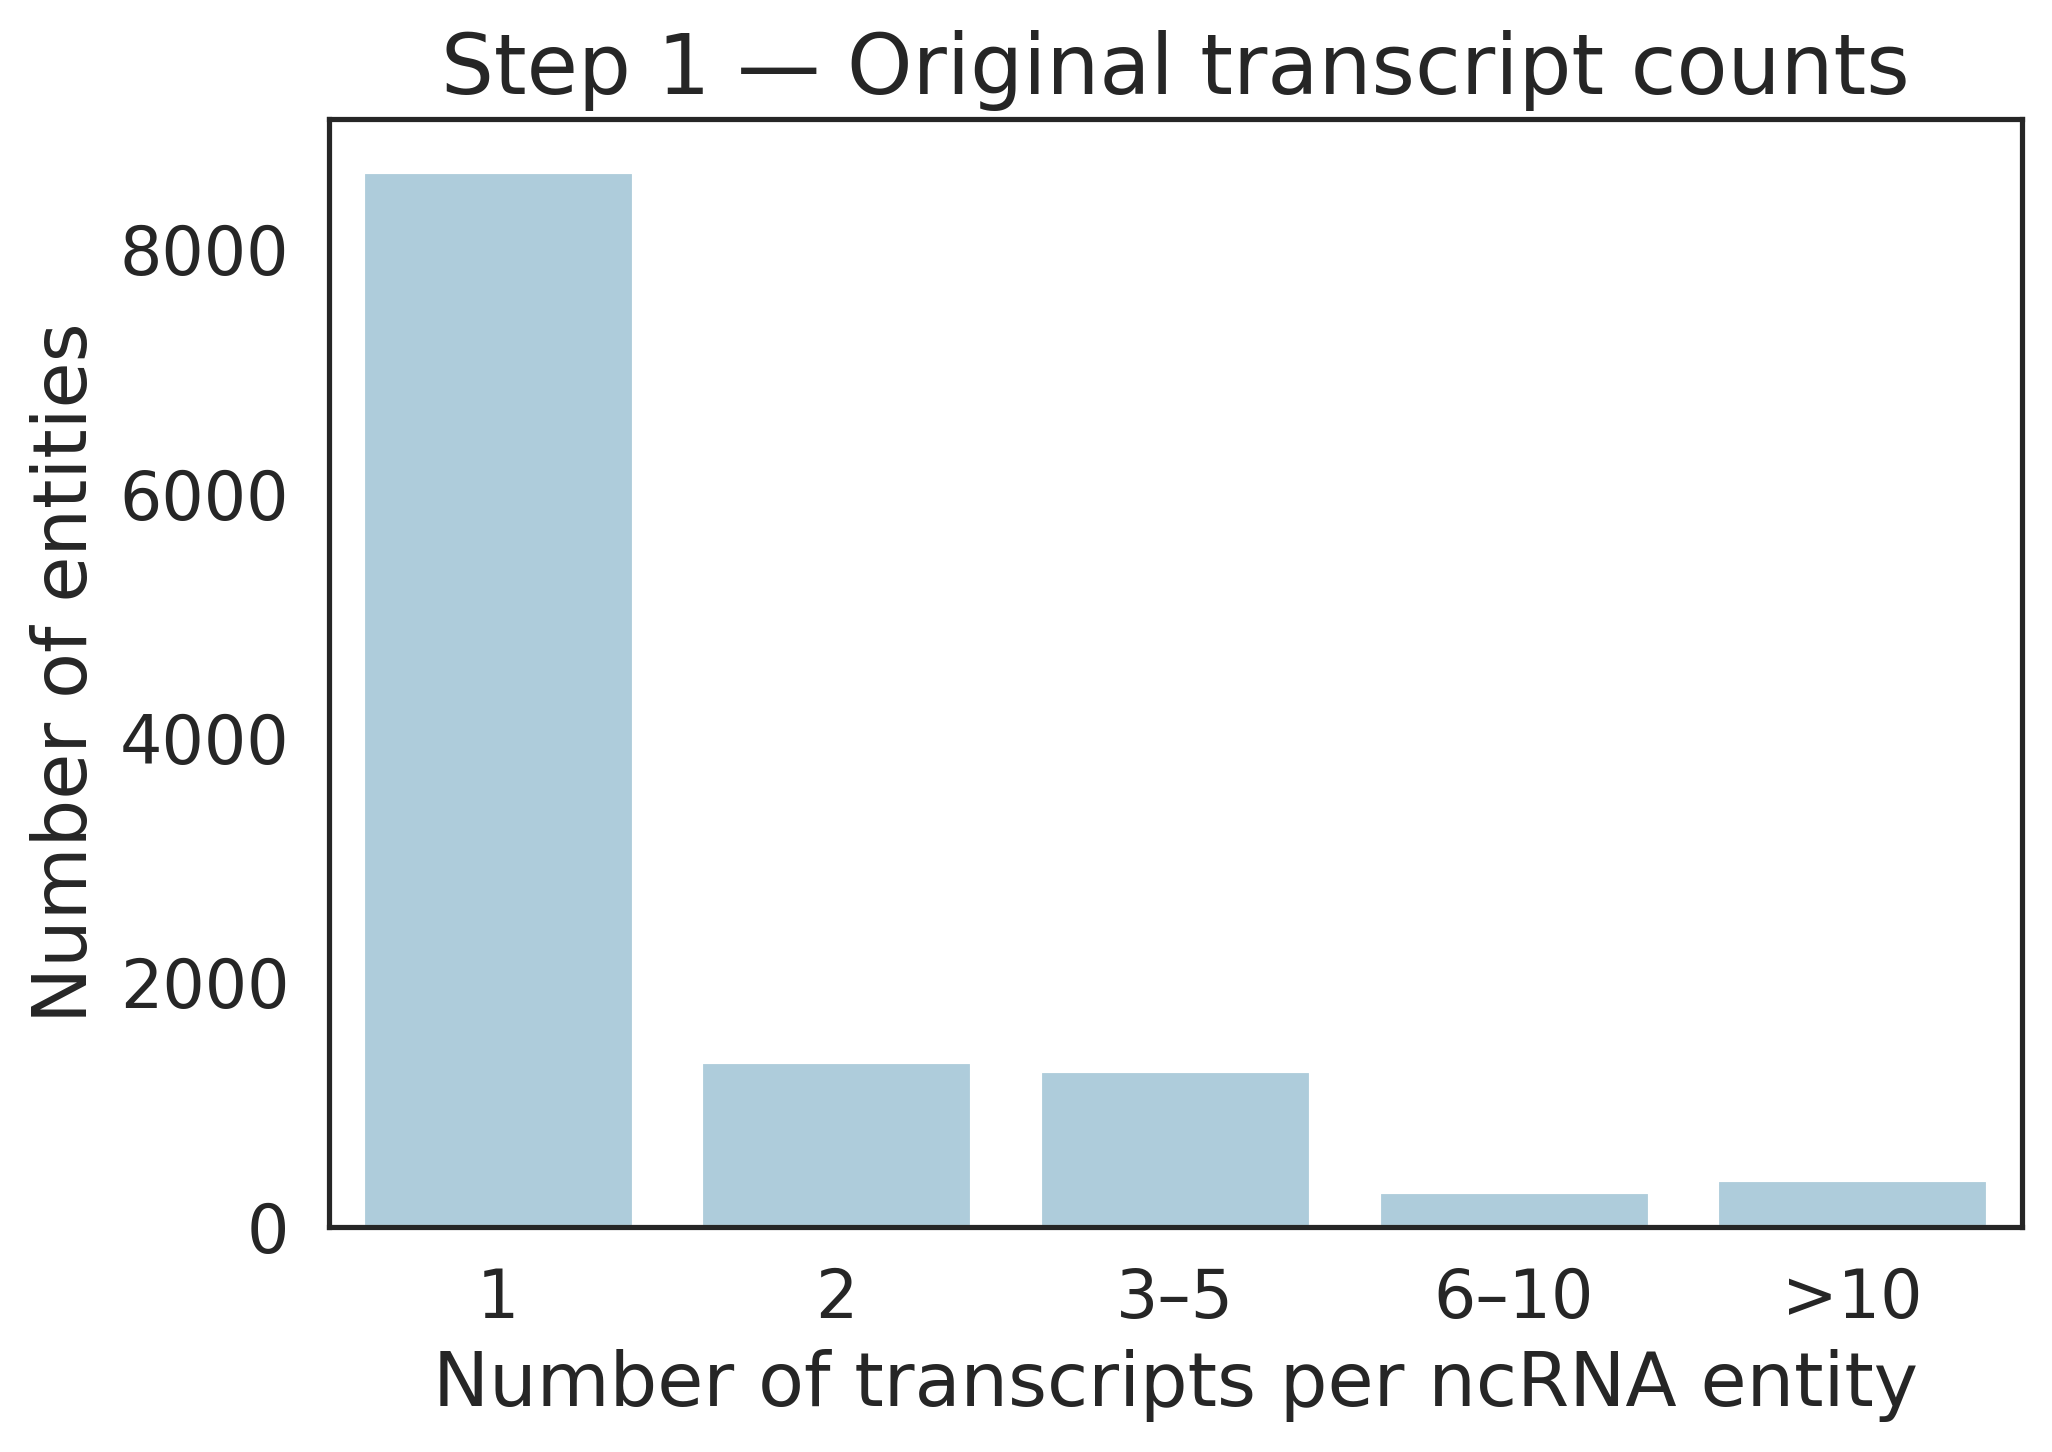

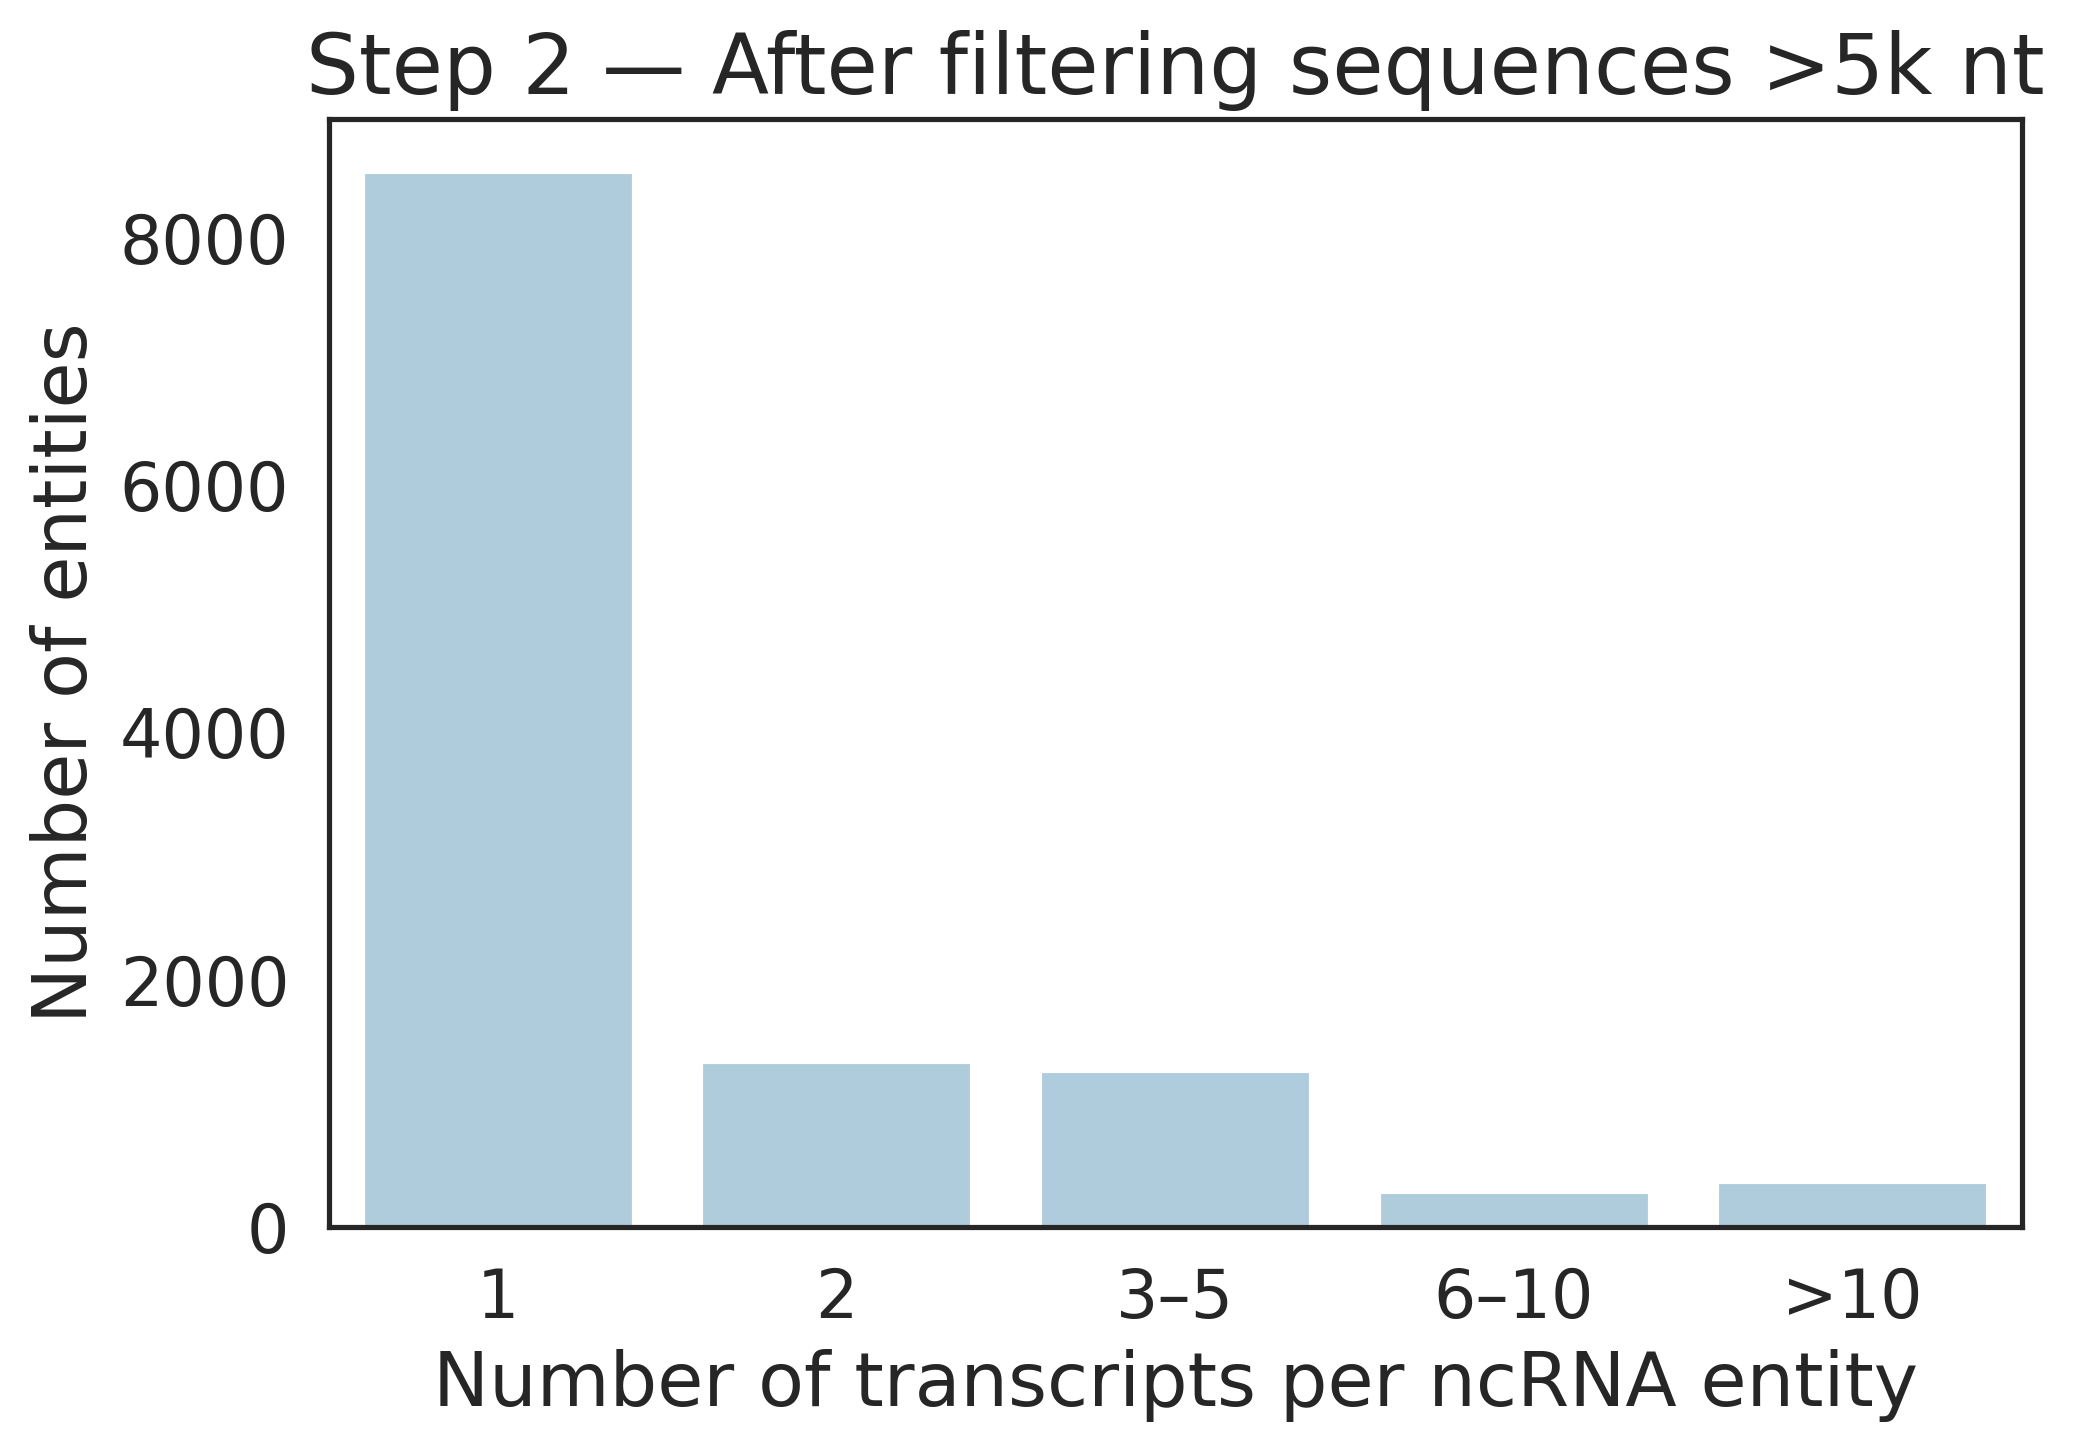

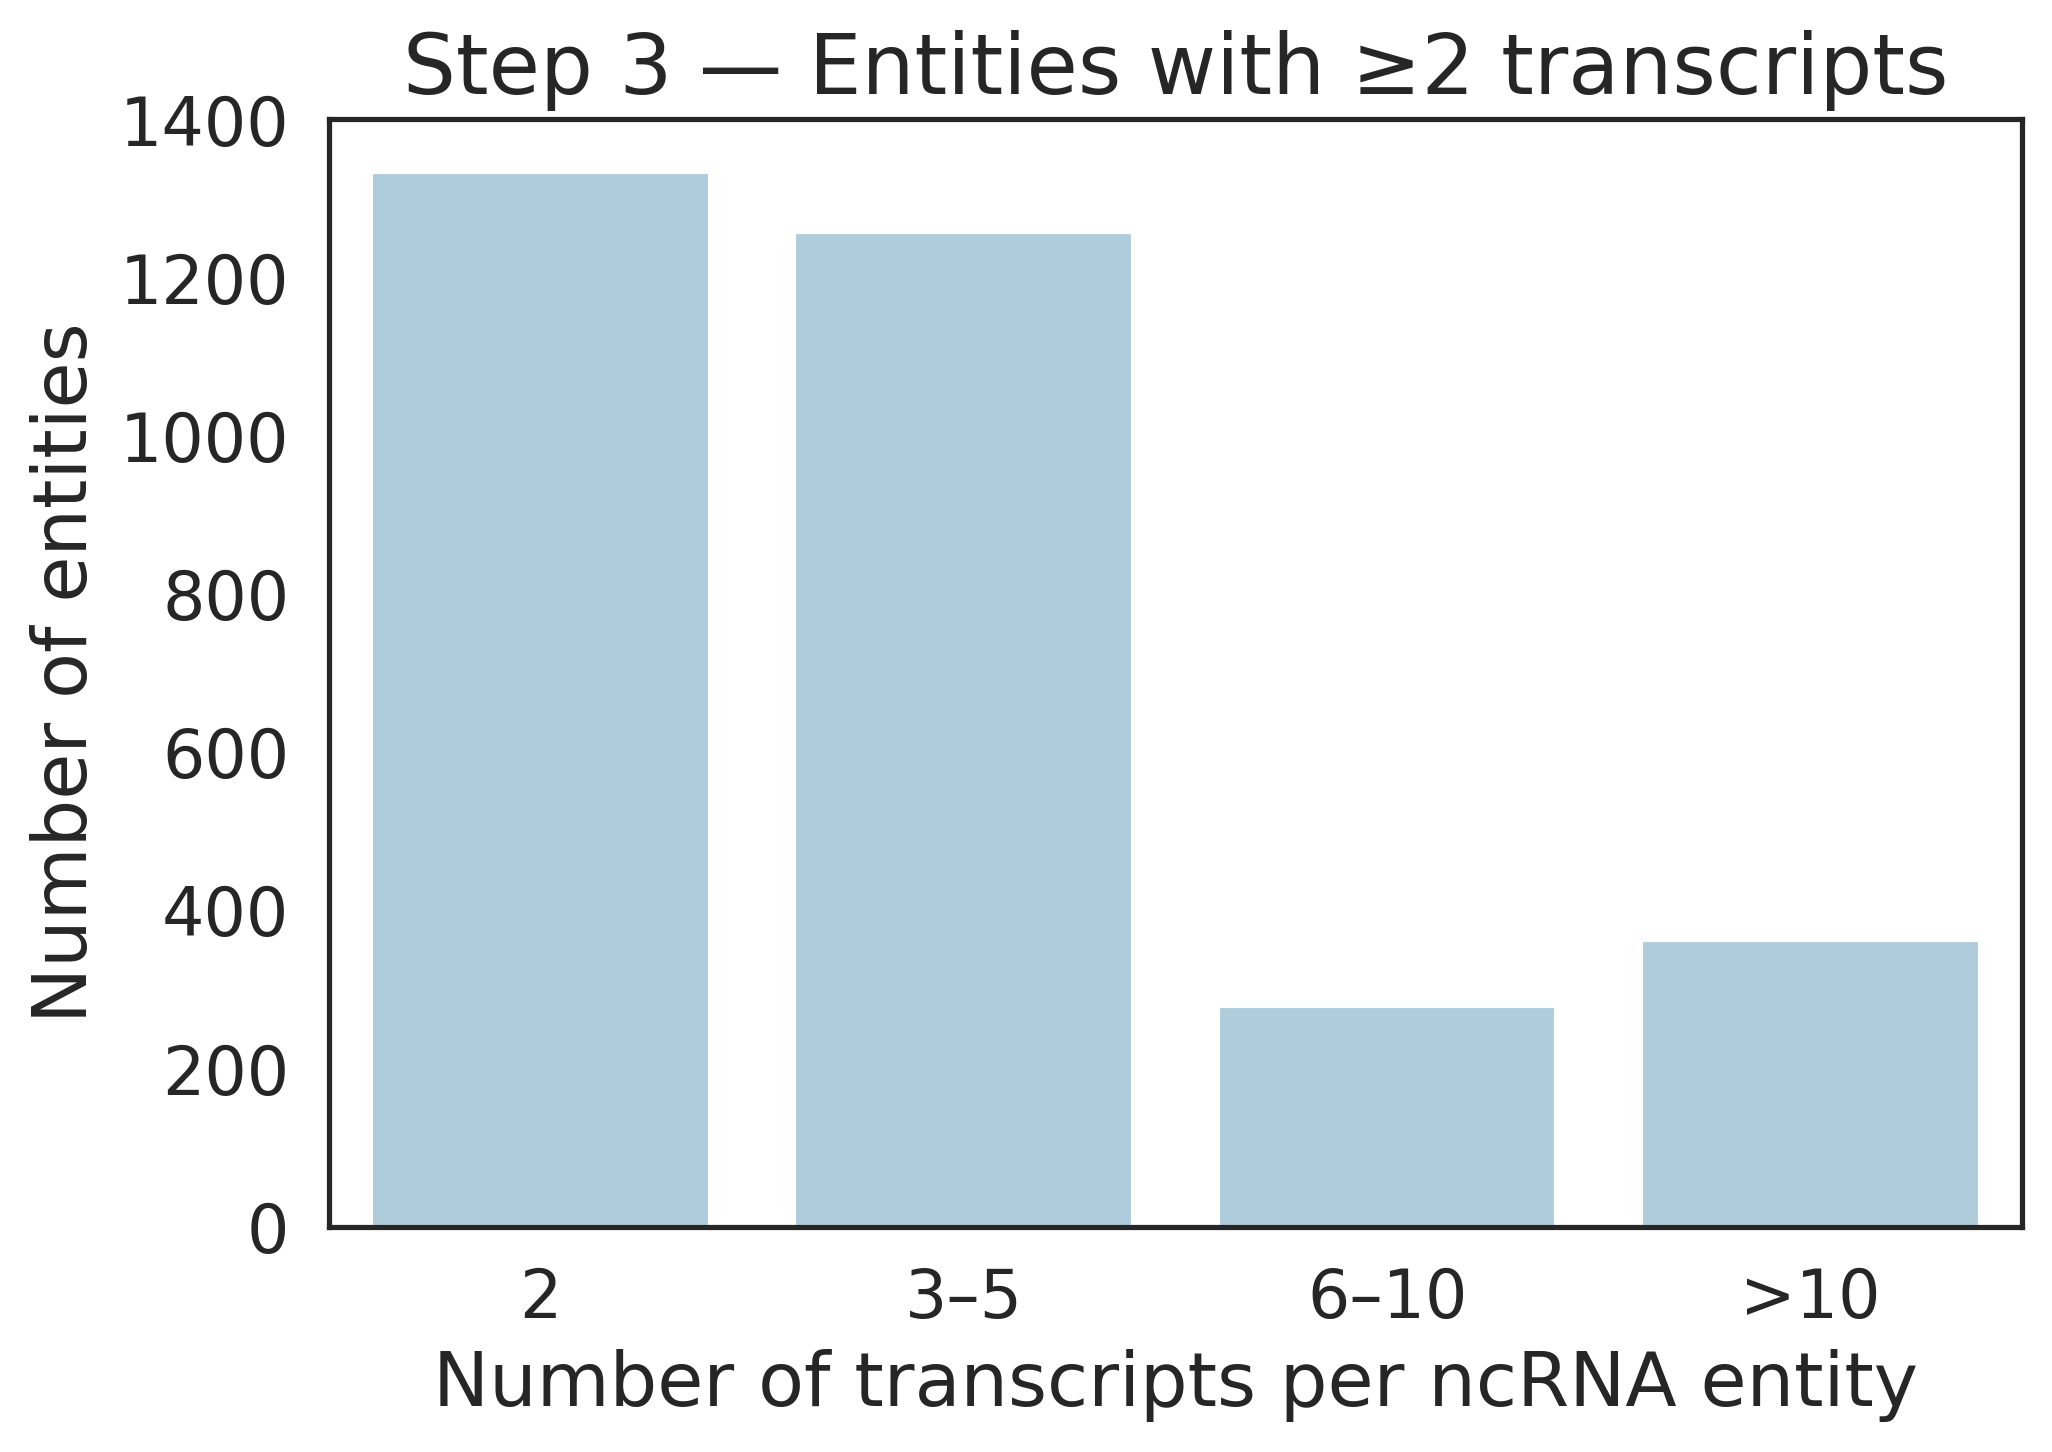

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

PASTEL_COLOR = "#A6CEE3"
sns.set_style("white")

bin_labels = ["1", "2", "3–5", "6–10", ">10"]

# -----------------------------
# Step 1 histogram based on bins
# -----------------------------
counts_step1 = df_step1["transcript_bin_orig"].value_counts().reindex(bin_labels, fill_value=0)
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step1.index, y=counts_step1.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 1 — Original transcript counts")
plt.tight_layout()
plt.show()

# -----------------------------
# Step 2 histogram based on bins
# -----------------------------
counts_step2 = df_step2[df_step2["n_transcripts_filtered"]>0]["transcript_bin_filtered"].value_counts().reindex(bin_labels, fill_value=0)
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step2.index, y=counts_step2.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 2 — After filtering sequences >5k nt")
plt.tight_layout()
plt.show()

# -----------------------------
# Step 3 histogram based on bins
# -----------------------------
counts_step3 = df_step3["transcript_bin_multi"].value_counts().reindex(bin_labels[1:], fill_value=0)  # remove "1"
plt.figure(figsize=(7,5), dpi=300)
sns.barplot(x=counts_step3.index, y=counts_step3.values, color=PASTEL_COLOR)
plt.xlabel("Number of transcripts per ncRNA entity")
plt.ylabel("Number of entities")
plt.title("Step 3 — Entities with ≥2 transcripts")
plt.tight_layout()
plt.show()

In [20]:
from itertools import combinations
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
import multiprocessing

# -----------------------------
# 1. Global identity (Needleman–Wunsch, globalxx)
# -----------------------------

from Bio.Align import PairwiseAligner

# -----------------------------
# 1. Global identity using PairwiseAligner
# -----------------------------
aligner = PairwiseAligner()
aligner.mode = 'global'
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = 0
aligner.extend_gap_score = 0

def global_identity(seq1, seq2):
    # Compute global alignment score
    score = aligner.score(seq1, seq2)
    # Normalize by length of alignment (max length)
    max_len = max(len(seq1), len(seq2))
    return score / max_len

# -----------------------------
# 2. Per-entity similarity statistics
# -----------------------------
def transcript_similarity_stats(seq_list):
    # Only valid sequences
    seqs = [s for s in seq_list if isinstance(s, str) and len(s) > 0]

    if len(seqs) < 2:
        return {
            "n_pairs": 0,
            "mean_sim": np.nan,
            "median_sim": np.nan,
            "min_sim": np.nan,
            "max_sim": np.nan,
            "var_sim": np.nan
        }

    sims = [global_identity(s1, s2) for s1, s2 in combinations(seqs, 2)]
    sims = np.array(sims)

    return {
        "n_pairs": len(sims),
        "mean_sim": sims.mean(),
        "median_sim": np.median(sims),
        "min_sim": sims.min(),
        "max_sim": sims.max(),
        "var_sim": sims.var()
    }

# -----------------------------
# 3. Parallel execution on Step 3 entities
# -----------------------------
n_cores = multiprocessing.cpu_count()

# Use df_step3 and the filtered seq_list
results = Parallel(n_jobs=n_cores)(
    delayed(transcript_similarity_stats)(seqs)
    for seqs in df_step3["seq_list_filtered"]
)

results_df = pd.DataFrame(results)

# Attach similarity statistics to df_step3
df_step3 = pd.concat(
    [df_step3.reset_index(drop=True), results_df],
    axis=1
)

print("Similarity computation complete.")

Similarity computation complete.


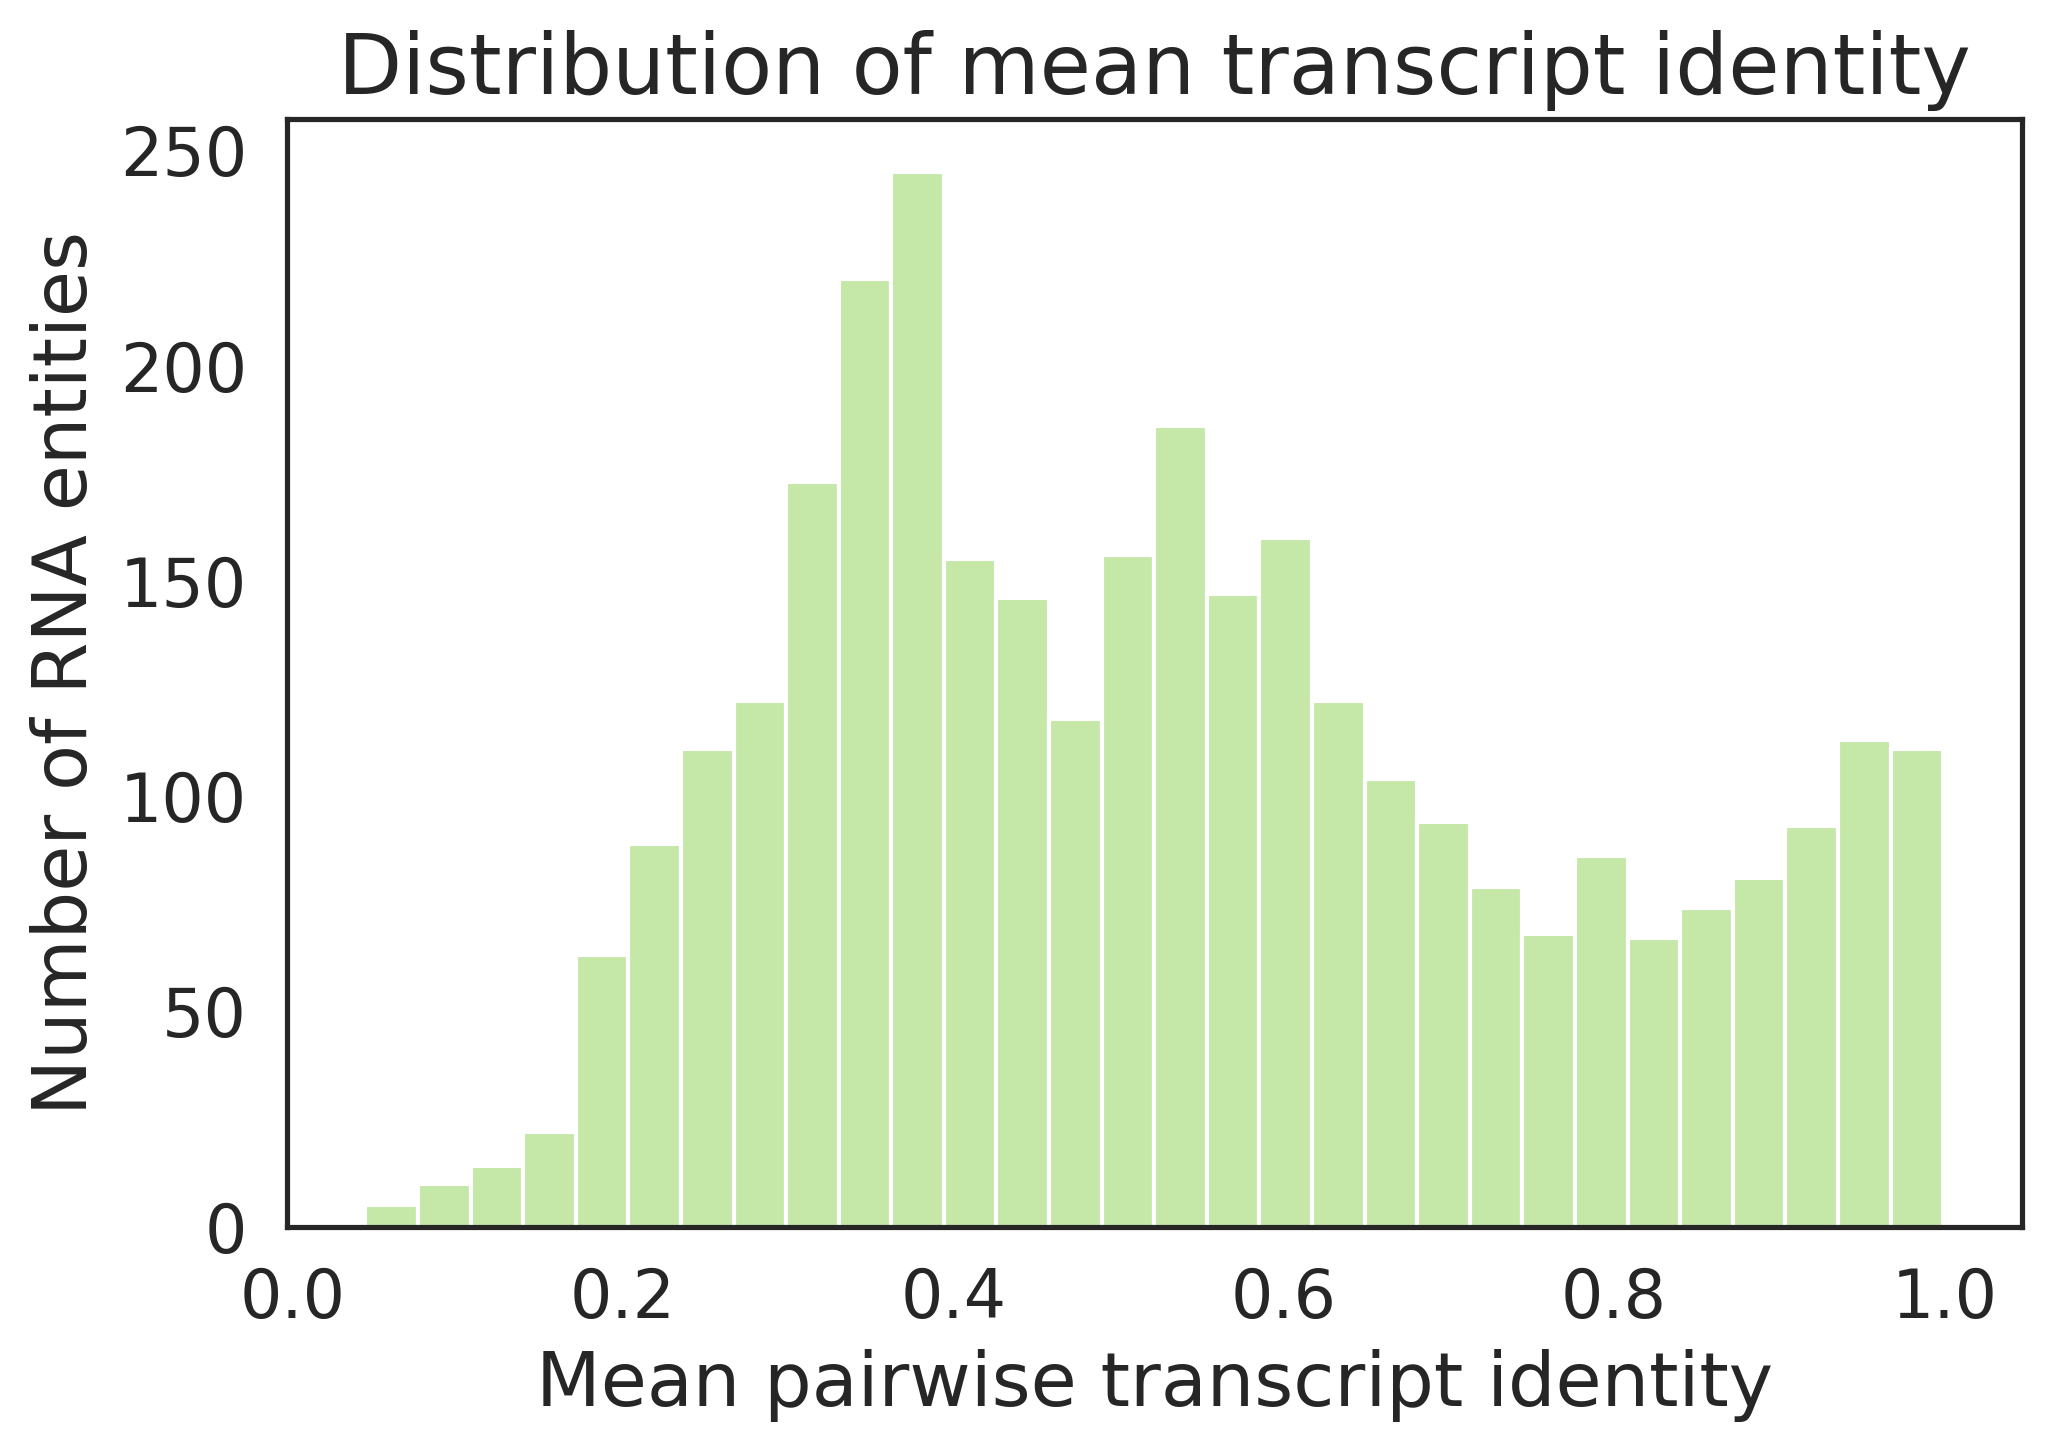

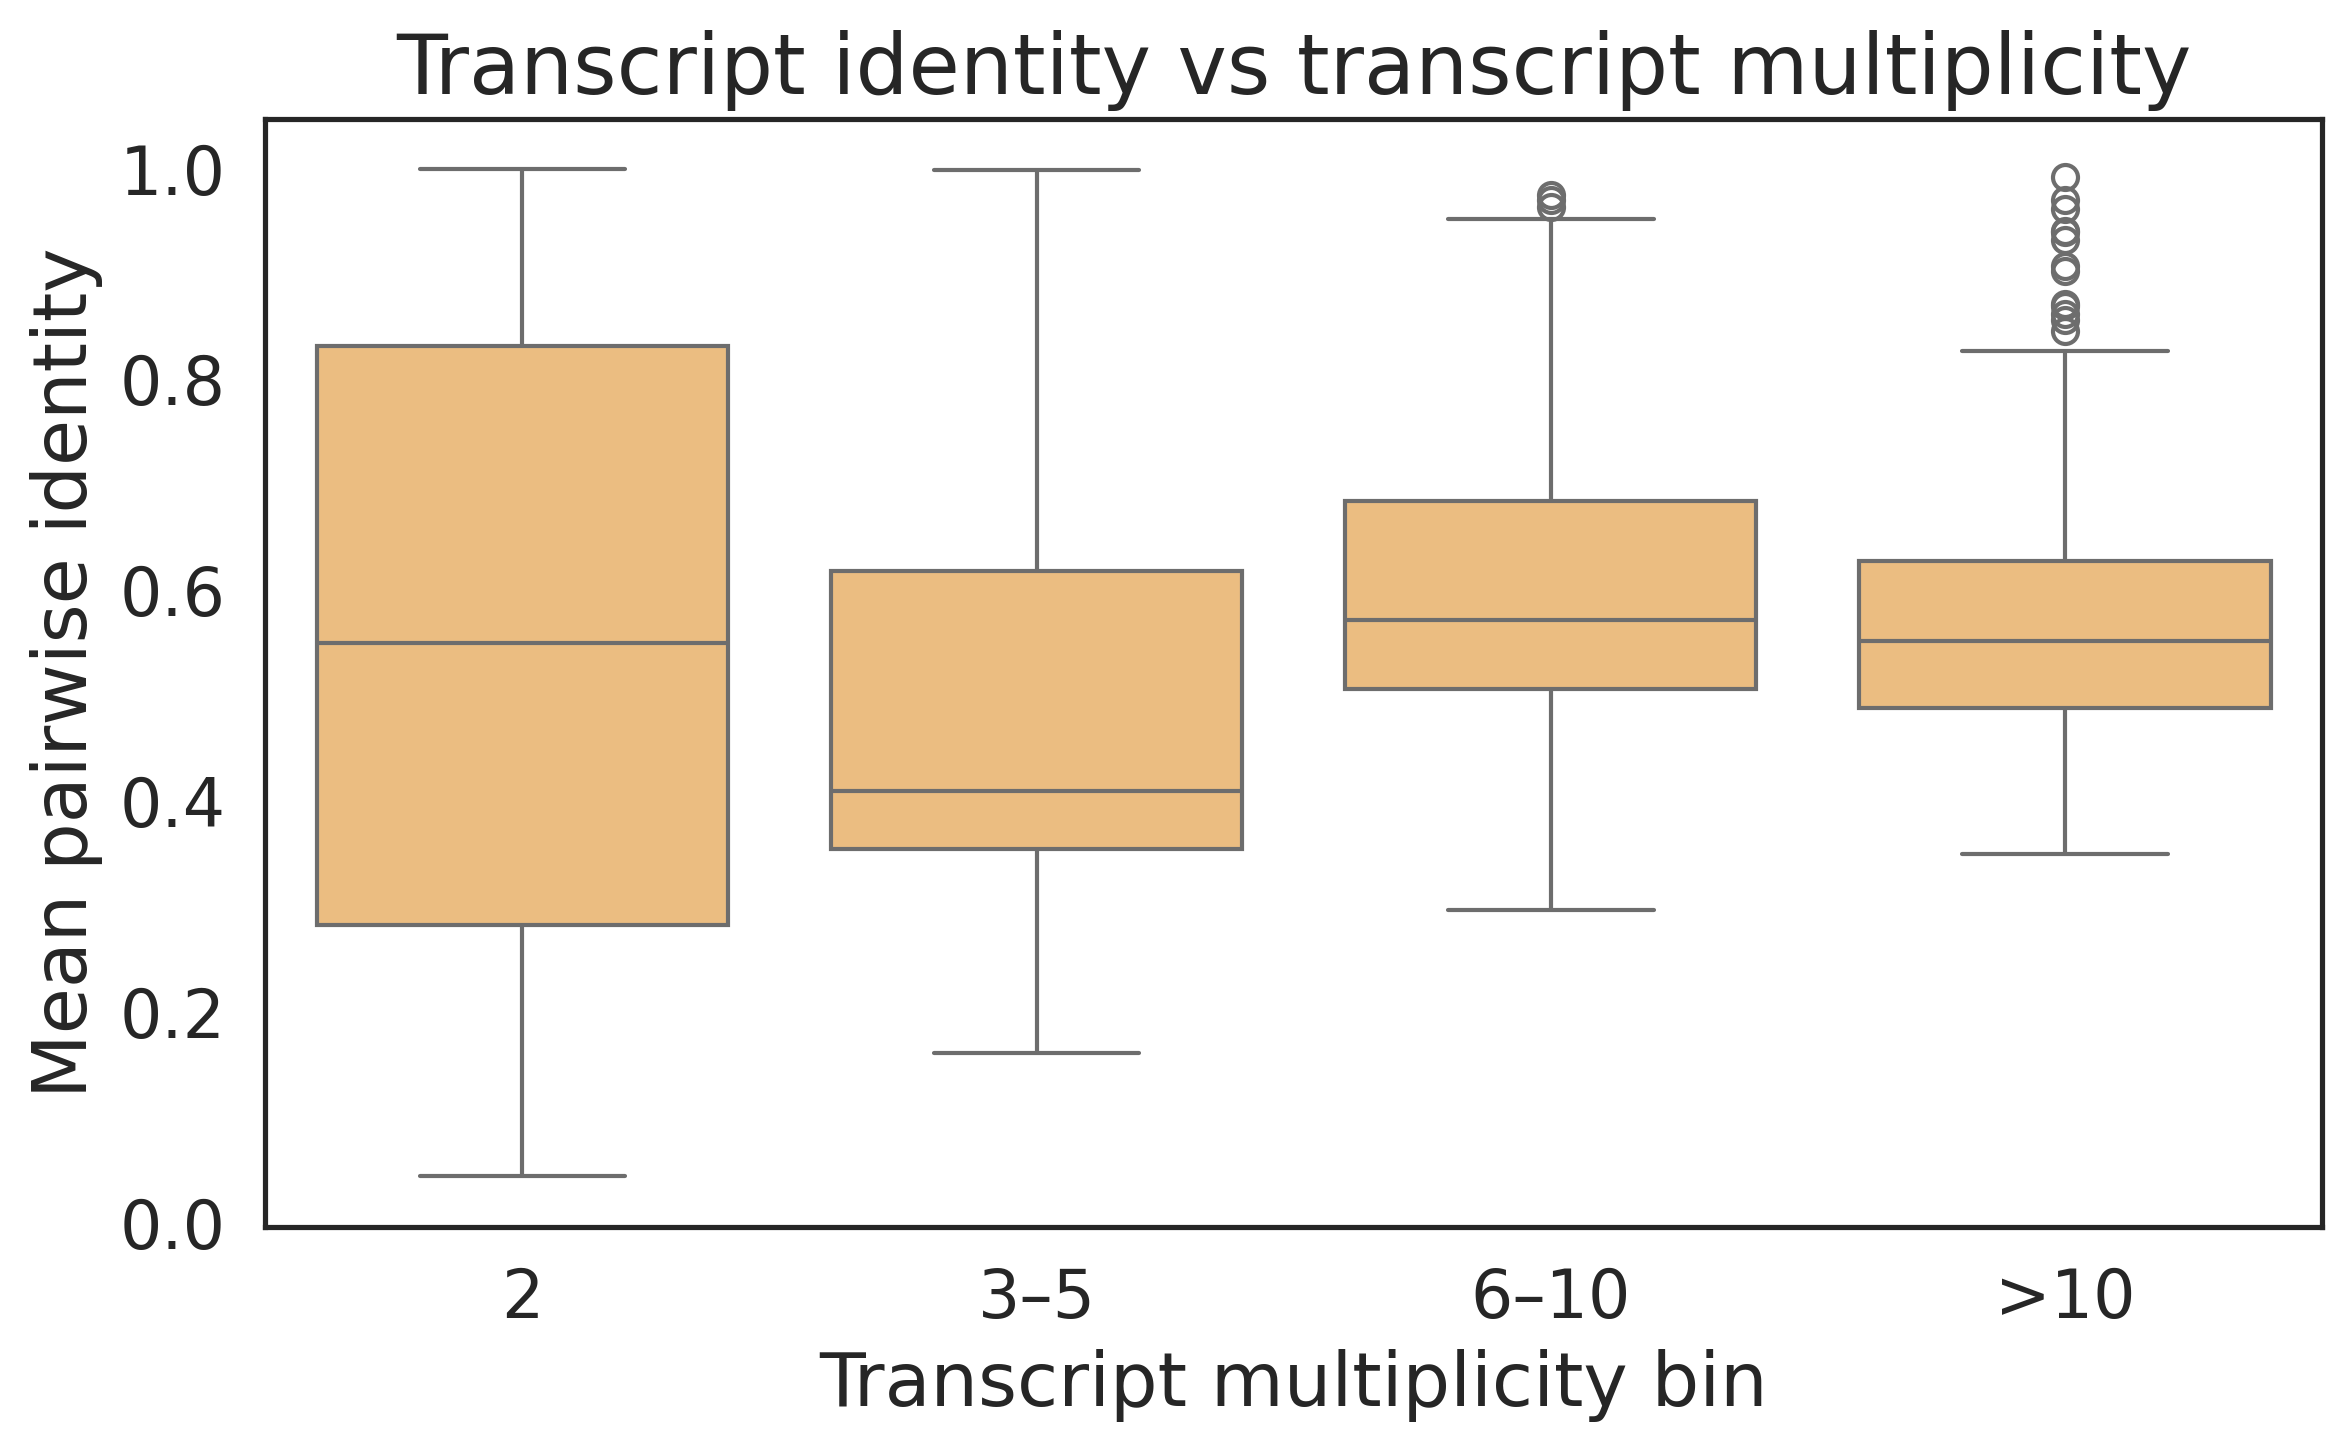

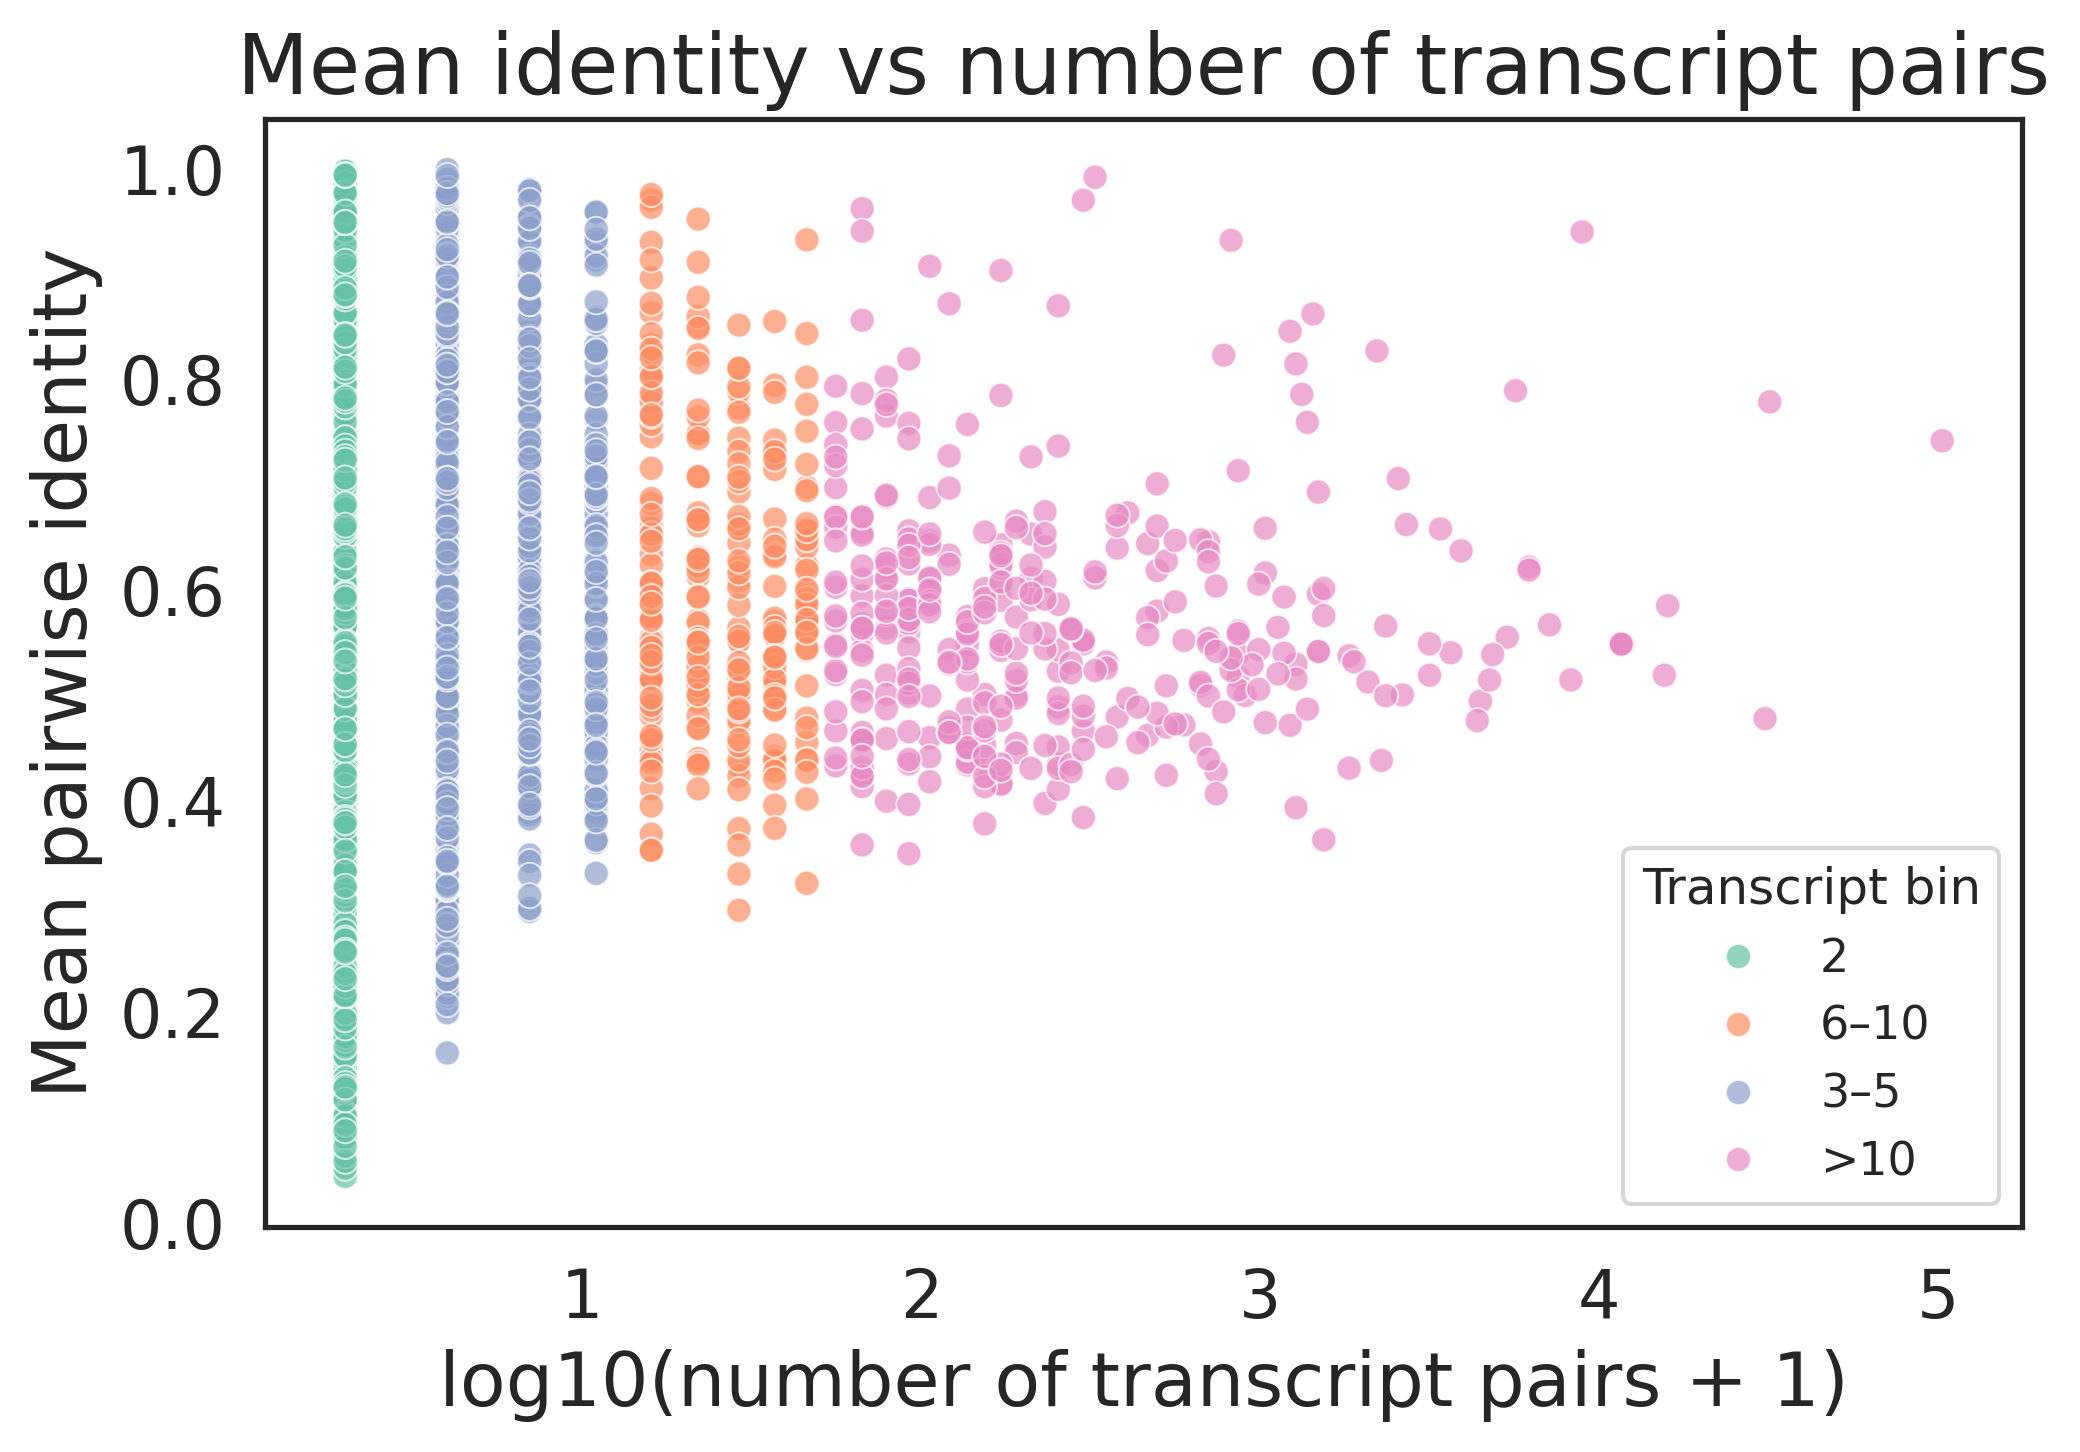

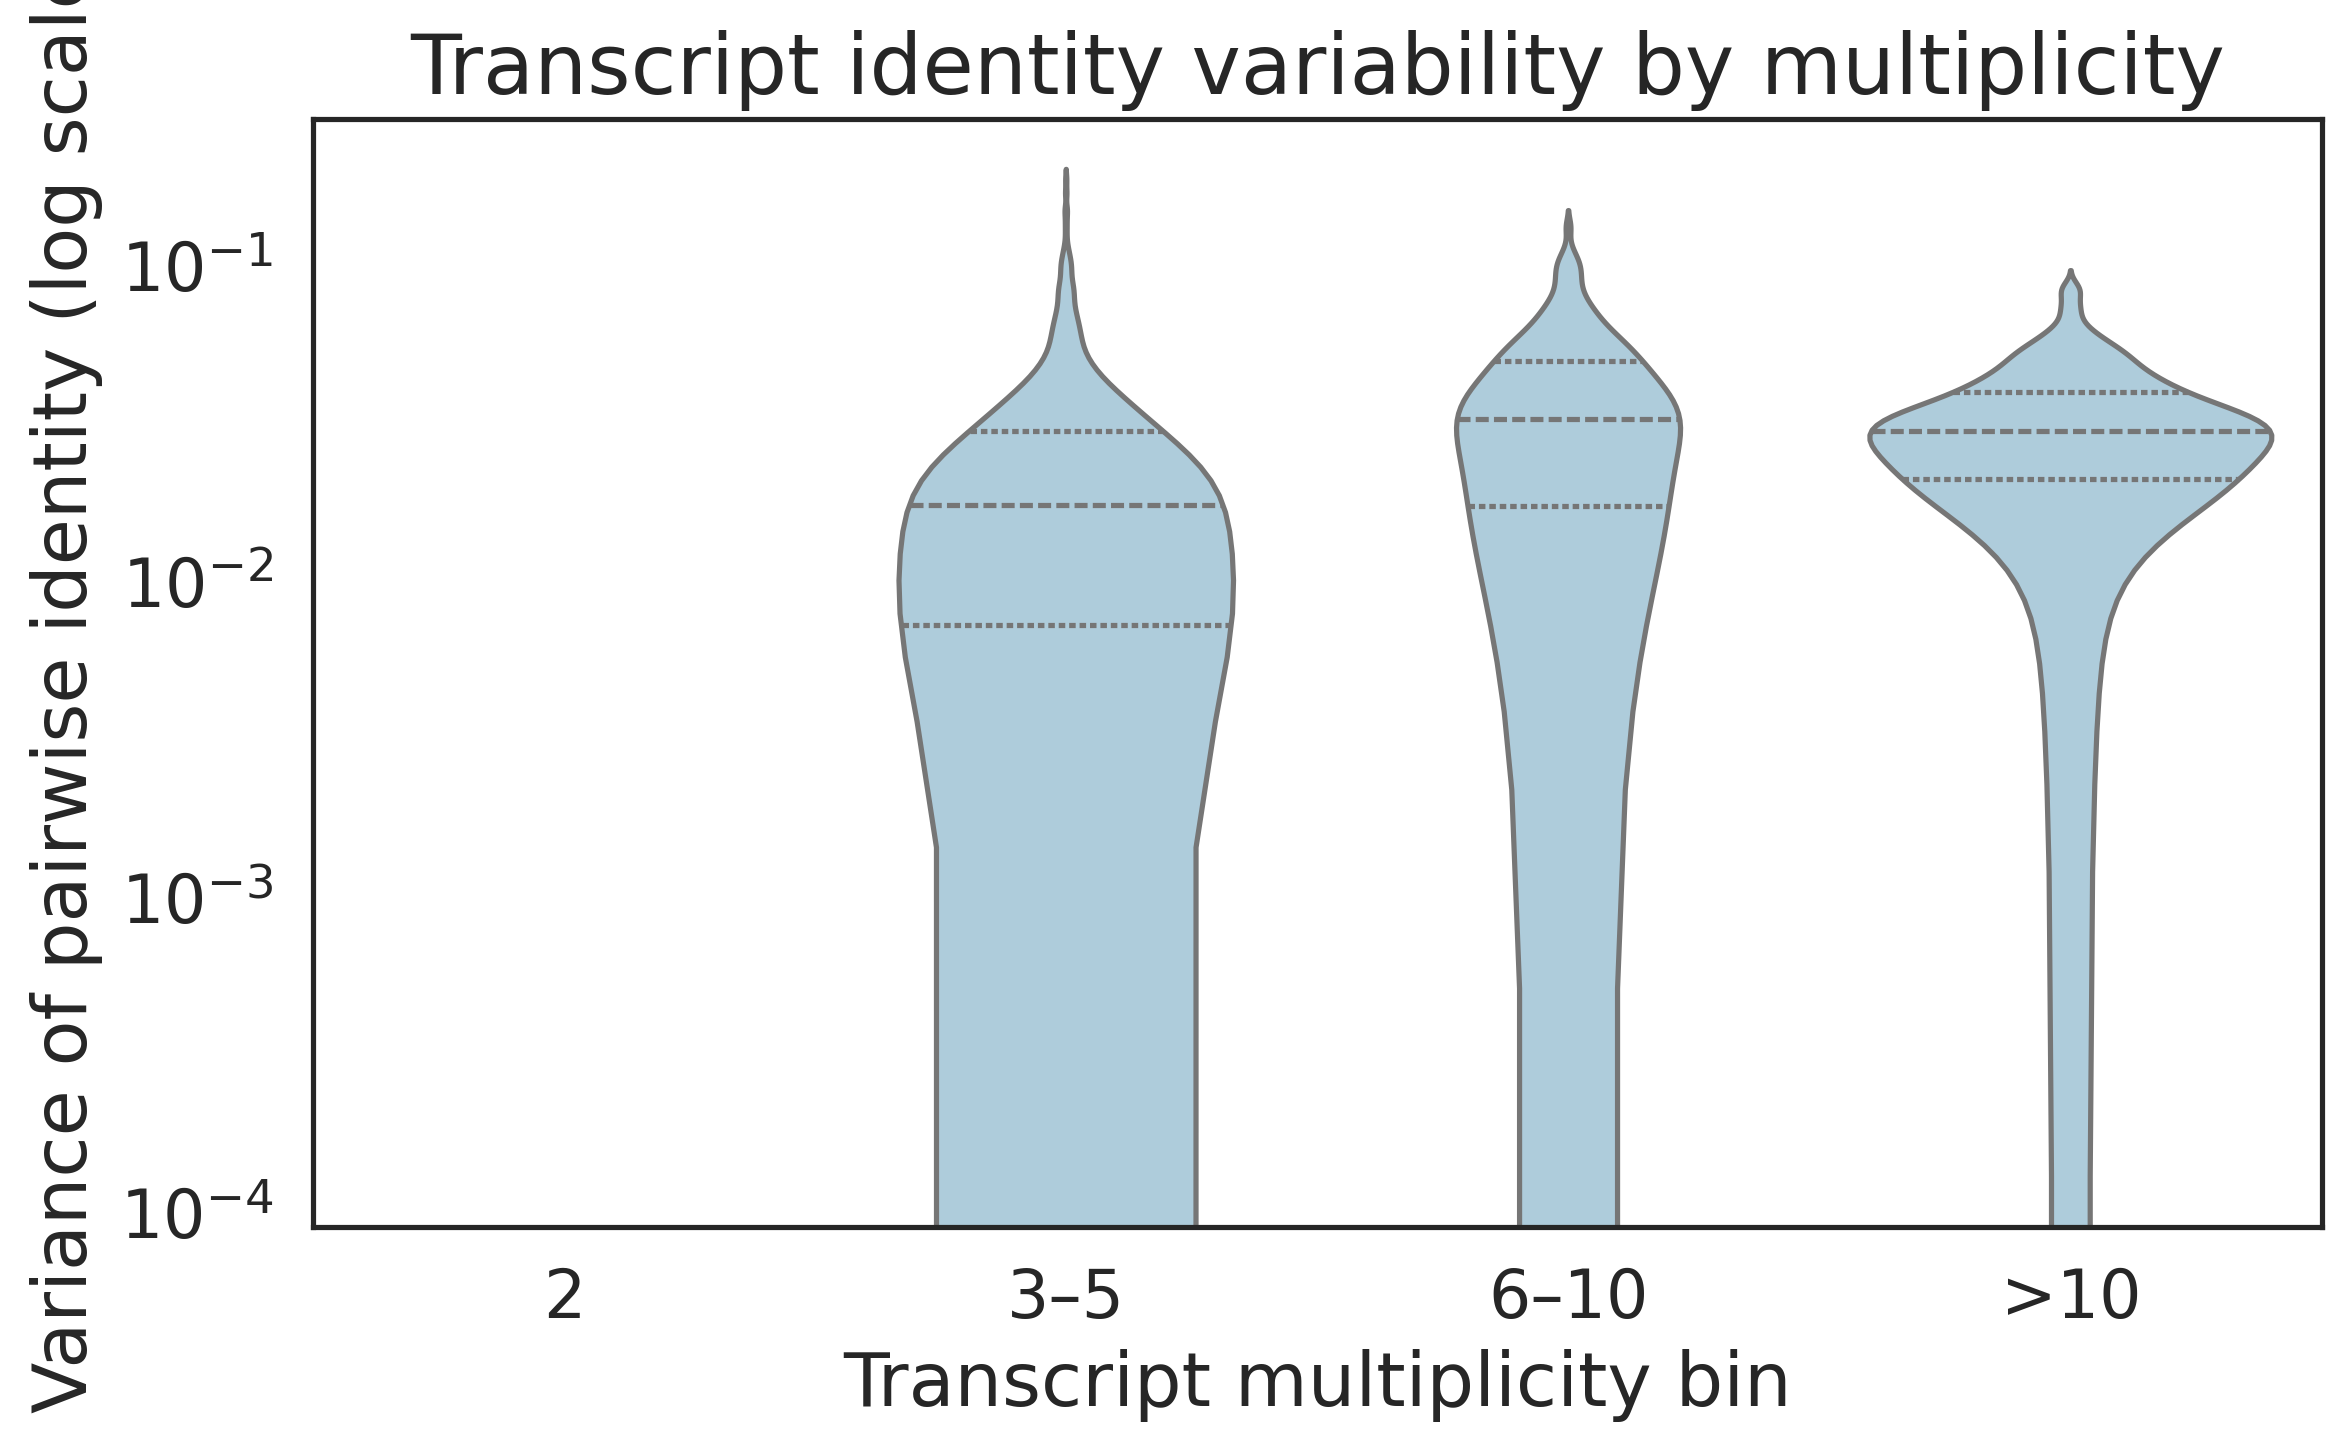

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

PASTEL_SIM = "#B2DF8A"
PASTEL_BOX = "#FDBF6F"
sns.set_style("white")

# --------------------------------------
# 1. Histogram of mean pairwise identity
# --------------------------------------
plt.figure(figsize=(7,5), dpi=300)
sns.histplot(df_step3["mean_sim"].dropna(), bins=30, color=PASTEL_SIM)
plt.xlabel("Mean pairwise transcript identity")
plt.ylabel("Number of RNA entities")
plt.title("Distribution of mean transcript identity")
plt.tight_layout()
plt.show()
plt.close()

# --------------------------------------
# 2. Boxplot of similarity by transcript multiplicity bins
# --------------------------------------
# Only bins "2", "3–5", "6–10", ">10"
bins_order = ["2", "3–5", "6–10", ">10"]
plt.figure(figsize=(8,5), dpi=300)
sns.boxplot(
    x="transcript_bin_multi",
    y="mean_sim",
    data=df_step3,
    order=bins_order,
    color=PASTEL_BOX
)
plt.xlabel("Transcript multiplicity bin")
plt.ylabel("Mean pairwise identity")
plt.title("Transcript identity vs transcript multiplicity")
plt.tight_layout()
plt.show()
plt.close()

# --------------------------------------
# 3. Scatter: number of pairs vs mean similarity
# --------------------------------------
df_step3["log_n_pairs"] = np.log10(df_step3["n_pairs"] + 1)  # avoid log(0)
plt.figure(figsize=(7,5), dpi=300)
sns.scatterplot(
    x="log_n_pairs",
    y="mean_sim",
    hue="transcript_bin_multi",
    palette="Set2",
    data=df_step3,
    alpha=0.7
)
plt.xlabel("log10(number of transcript pairs + 1)")
plt.ylabel("Mean pairwise identity")
plt.title("Mean identity vs number of transcript pairs")
plt.legend(title="Transcript bin")
plt.tight_layout()
plt.show()
plt.close()

# --------------------------------------
# 4. Violin plot of variability (variance of pairwise similarity) by bin
# --------------------------------------
plt.figure(figsize=(8,5), dpi=300)
sns.violinplot(
    x="transcript_bin_multi",
    y="var_sim",
    data=df_step3,
    order=bins_order,
    inner="quartile",
    color="#A6CEE3"
)
plt.yscale("log")  # variance can be highly skewed
plt.xlabel("Transcript multiplicity bin")
plt.ylabel("Variance of pairwise identity (log scale)")
plt.title("Transcript identity variability by multiplicity")
plt.tight_layout()
plt.show()
plt.close()

In [22]:
# --------------------------------------
# Summary statistics across all entities
# --------------------------------------
print("=== Overall transcript similarity statistics ===")
print("Number of entities:", len(df_step3))
print("Mean of mean_sim:", df_step3["mean_sim"].mean())
print("Median of mean_sim:", df_step3["mean_sim"].median())
print("Min/Max mean_sim:", df_step3["mean_sim"].min(), df_step3["mean_sim"].max())
print("Mean of var_sim:", df_step3["var_sim"].mean())
print("Median of var_sim:", df_step3["var_sim"].median())
print("Min/Max var_sim:", df_step3["var_sim"].min(), df_step3["var_sim"].max())
print("Mean number of transcript pairs per entity:", df_step3["n_pairs"].mean())
print("Median number of transcript pairs per entity:", df_step3["n_pairs"].median())
print()

# --------------------------------------
# Summary per transcript multiplicity bin
# --------------------------------------
print("=== Transcript similarity statistics by multiplicity bin ===")
bins_order = ["2", "3–5", "6–10", ">10"]
for b in bins_order:
    sub = df_step3[df_step3["transcript_bin_multi"] == b]
    print(f"Bin '{b}': n_entities={len(sub)}")
    print(f"  mean mean_sim: {sub['mean_sim'].mean():.3f}")
    print(f"  median mean_sim: {sub['mean_sim'].median():.3f}")
    print(f"  mean var_sim: {sub['var_sim'].mean():.4f}")
    print(f"  median var_sim: {sub['var_sim'].median():.4f}")
    print(f"  mean n_pairs: {sub['n_pairs'].mean():.1f}")
    print(f"  median n_pairs: {sub['n_pairs'].median():.1f}")
    print()

=== Overall transcript similarity statistics ===
Number of entities: 3234
Mean of mean_sim: 0.5405872873592679
Median of mean_sim: 0.5158206590923626
Min/Max mean_sim: 0.04409489427539969 0.9992283950617284
Mean of var_sim: 0.015752377381137685
Median of var_sim: 0.005402859374267786
Min/Max var_sim: 0.0 0.19141126819606055
Mean number of transcript pairs per entity: 152.13667285095858
Median number of transcript pairs per entity: 3.0

=== Transcript similarity statistics by multiplicity bin ===
Bin '2': n_entities=1334
  mean mean_sim: 0.561
  median mean_sim: 0.550
  mean var_sim: 0.0000
  median var_sim: 0.0000
  mean n_pairs: 1.0
  median n_pairs: 1.0

Bin '3–5': n_entities=1258
  mean mean_sim: 0.496
  median mean_sim: 0.410
  mean var_sim: 0.0232
  median var_sim: 0.0175
  mean n_pairs: 4.1
  median n_pairs: 3.0

Bin '6–10': n_entities=279
  mean mean_sim: 0.602
  median mean_sim: 0.572
  mean var_sim: 0.0365
  median var_sim: 0.0328
  mean n_pairs: 26.1
  median n_pairs: 21.0

B

In [31]:
# Define threshold
SIM_THRESHOLD = 0.5

# Count entities that would be removed
n_total = len(df_step3)
n_removed = (df_step3["mean_sim"] < SIM_THRESHOLD).sum()
n_kept = n_total - n_removed

print(f"Total entities: {n_total}")
print(f"Entities below mean_sim {SIM_THRESHOLD}: {n_removed} ({n_removed/n_total:.1%})")
print(f"Entities above mean_sim {SIM_THRESHOLD}: {n_kept} ({n_kept/n_total:.1%})")

Total entities: 3234
Entities below mean_sim 0.5: 1530 (47.3%)
Entities above mean_sim 0.5: 1704 (52.7%)


<h2>Need to fix the following part:</h2>

In [36]:
from itertools import combinations
import numpy as np
import pandas as pd
from Bio.Align import PairwiseAligner
from joblib import Parallel, delayed
import multiprocessing

# ------------------------------------------------------------
# 1. Filter sequences by length (<4096 nt)
# ------------------------------------------------------------
MAX_SEQ_LEN = 4096

df_ncrna_unique["seq_list_filtered_len"] = df_ncrna_unique["seq_list"].apply(
    lambda x: [s for s in valid_sequences(x) if len(s) <= MAX_SEQ_LEN]
)

# Only keep entities with >=2 filtered transcripts
df_step2_len = df_ncrna_unique[
    df_ncrna_unique["seq_list_filtered_len"].apply(len) >= 2
].copy()

print("Step 1 — Entities after length filter (>=2 transcripts, <=4096 nt):", len(df_step2_len))

# ------------------------------------------------------------
# 2. Global identity using PairwiseAligner
# ------------------------------------------------------------
aligner = PairwiseAligner()
aligner.mode = 'global'
aligner.match_score = 1
aligner.mismatch_score = 0
aligner.open_gap_score = 0
aligner.extend_gap_score = 0

def global_identity(seq1, seq2):
    score = aligner.score(seq1, seq2)
    max_len = max(len(seq1), len(seq2))
    return score / max_len

# ------------------------------------------------------------
# 3. Per-entity similarity stats
# ------------------------------------------------------------
def transcript_similarity_stats(seq_list):
    seqs = [s for s in seq_list if isinstance(s, str) and len(s) > 0]
    if len(seqs) < 2:
        return {"n_pairs": 0, "mean_sim": np.nan}
    sims = [global_identity(s1, s2) for s1, s2 in combinations(seqs, 2)]
    sims = np.array(sims)
    return {"n_pairs": len(sims), "mean_sim": sims.mean()}

# ------------------------------------------------------------
# 4. Parallel computation
# ------------------------------------------------------------
n_cores = multiprocessing.cpu_count()
results = Parallel(n_jobs=n_cores)(
    delayed(transcript_similarity_stats)(seqs)
    for seqs in df_step2_len["seq_list_filtered_len"]
)
results_df = pd.DataFrame(results)
df_step2_len = pd.concat([df_step2_len.reset_index(drop=True), results_df], axis=1)

print("Similarity computation complete. Example mean_sim:")
print(df_step2_len["mean_sim"].describe())

# ------------------------------------------------------------
# 5. Filter entities by mean similarity threshold
# ------------------------------------------------------------
SIM_THRESHOLD = 0.0  # example, can adjust

df_final = df_step2_len[df_step2_len["mean_sim"] >= SIM_THRESHOLD].copy()
print(f"Entities retained above mean_sim >= {SIM_THRESHOLD}:", len(df_final))
print(f"Entities removed:", len(df_step2_len) - len(df_final))

# ------------------------------------------------------------
# 6. Count interactions lost if entities are removed
# ------------------------------------------------------------
# Assume original interactions dataframe: df
# Merge entity keys for both sides
entity_keys = df_ncrna_unique["entity_key"].to_dict()
key_map = {i: k for i, k in enumerate(df_ncrna_unique["entity_key"])}

# Create sets of retained entities
retained_keys = set(df_final["entity_key"])

# Interactions to keep
def interaction_retained(row):
    key1 = make_entity_key(row["Interactor1.Symbol"], row["Category1_std"], row["Species1"], row["Raw_ID1_list"])
    key2 = make_entity_key(row["Interactor2.Symbol"], row["Category2_std"], row["Species2"], row["Raw_ID2_list"])
    return (key1 in retained_keys) and (key2 in retained_keys)

interactions_kept = df[df.apply(interaction_retained, axis=1)]
interactions_lost = len(df) - len(interactions_kept)

print("Total interactions:", len(df))
print("Interactions retained after filtering:", len(interactions_kept))
print("Interactions lost:", interactions_lost)

# ------------------------------------------------------------
# 7. Save filtered entities
# ------------------------------------------------------------
df_final.to_pickle("ncrna_entities_final_filtered.pkl")
print("Saved: ncrna_entities_final_filtered.pkl")

Step 1 — Entities after length filter (>=2 transcripts, <=4096 nt): 3193
Similarity computation complete. Example mean_sim:
count    3193.000000
mean        0.542683
std         0.224948
min         0.044095
25%         0.362123
50%         0.519863
75%         0.699801
max         0.999228
Name: mean_sim, dtype: float64
Entities retained above mean_sim >= 0.0: 3193
Entities removed: 0
Total interactions: 82171
Interactions retained after filtering: 2659
Interactions lost: 79512
Saved: ncrna_entities_final_filtered.pkl


Number of unique RNA entities remaining: 11928
Number of unique sequences remaining: 25797

=== Transcript length distribution after filtering ===
Number of transcripts: 29086
Min length: 11
Max length: 4096
Mean length: 886.4285566939421
Median length: 648.0
25th percentile: 98.25
75th percentile: 1314.0


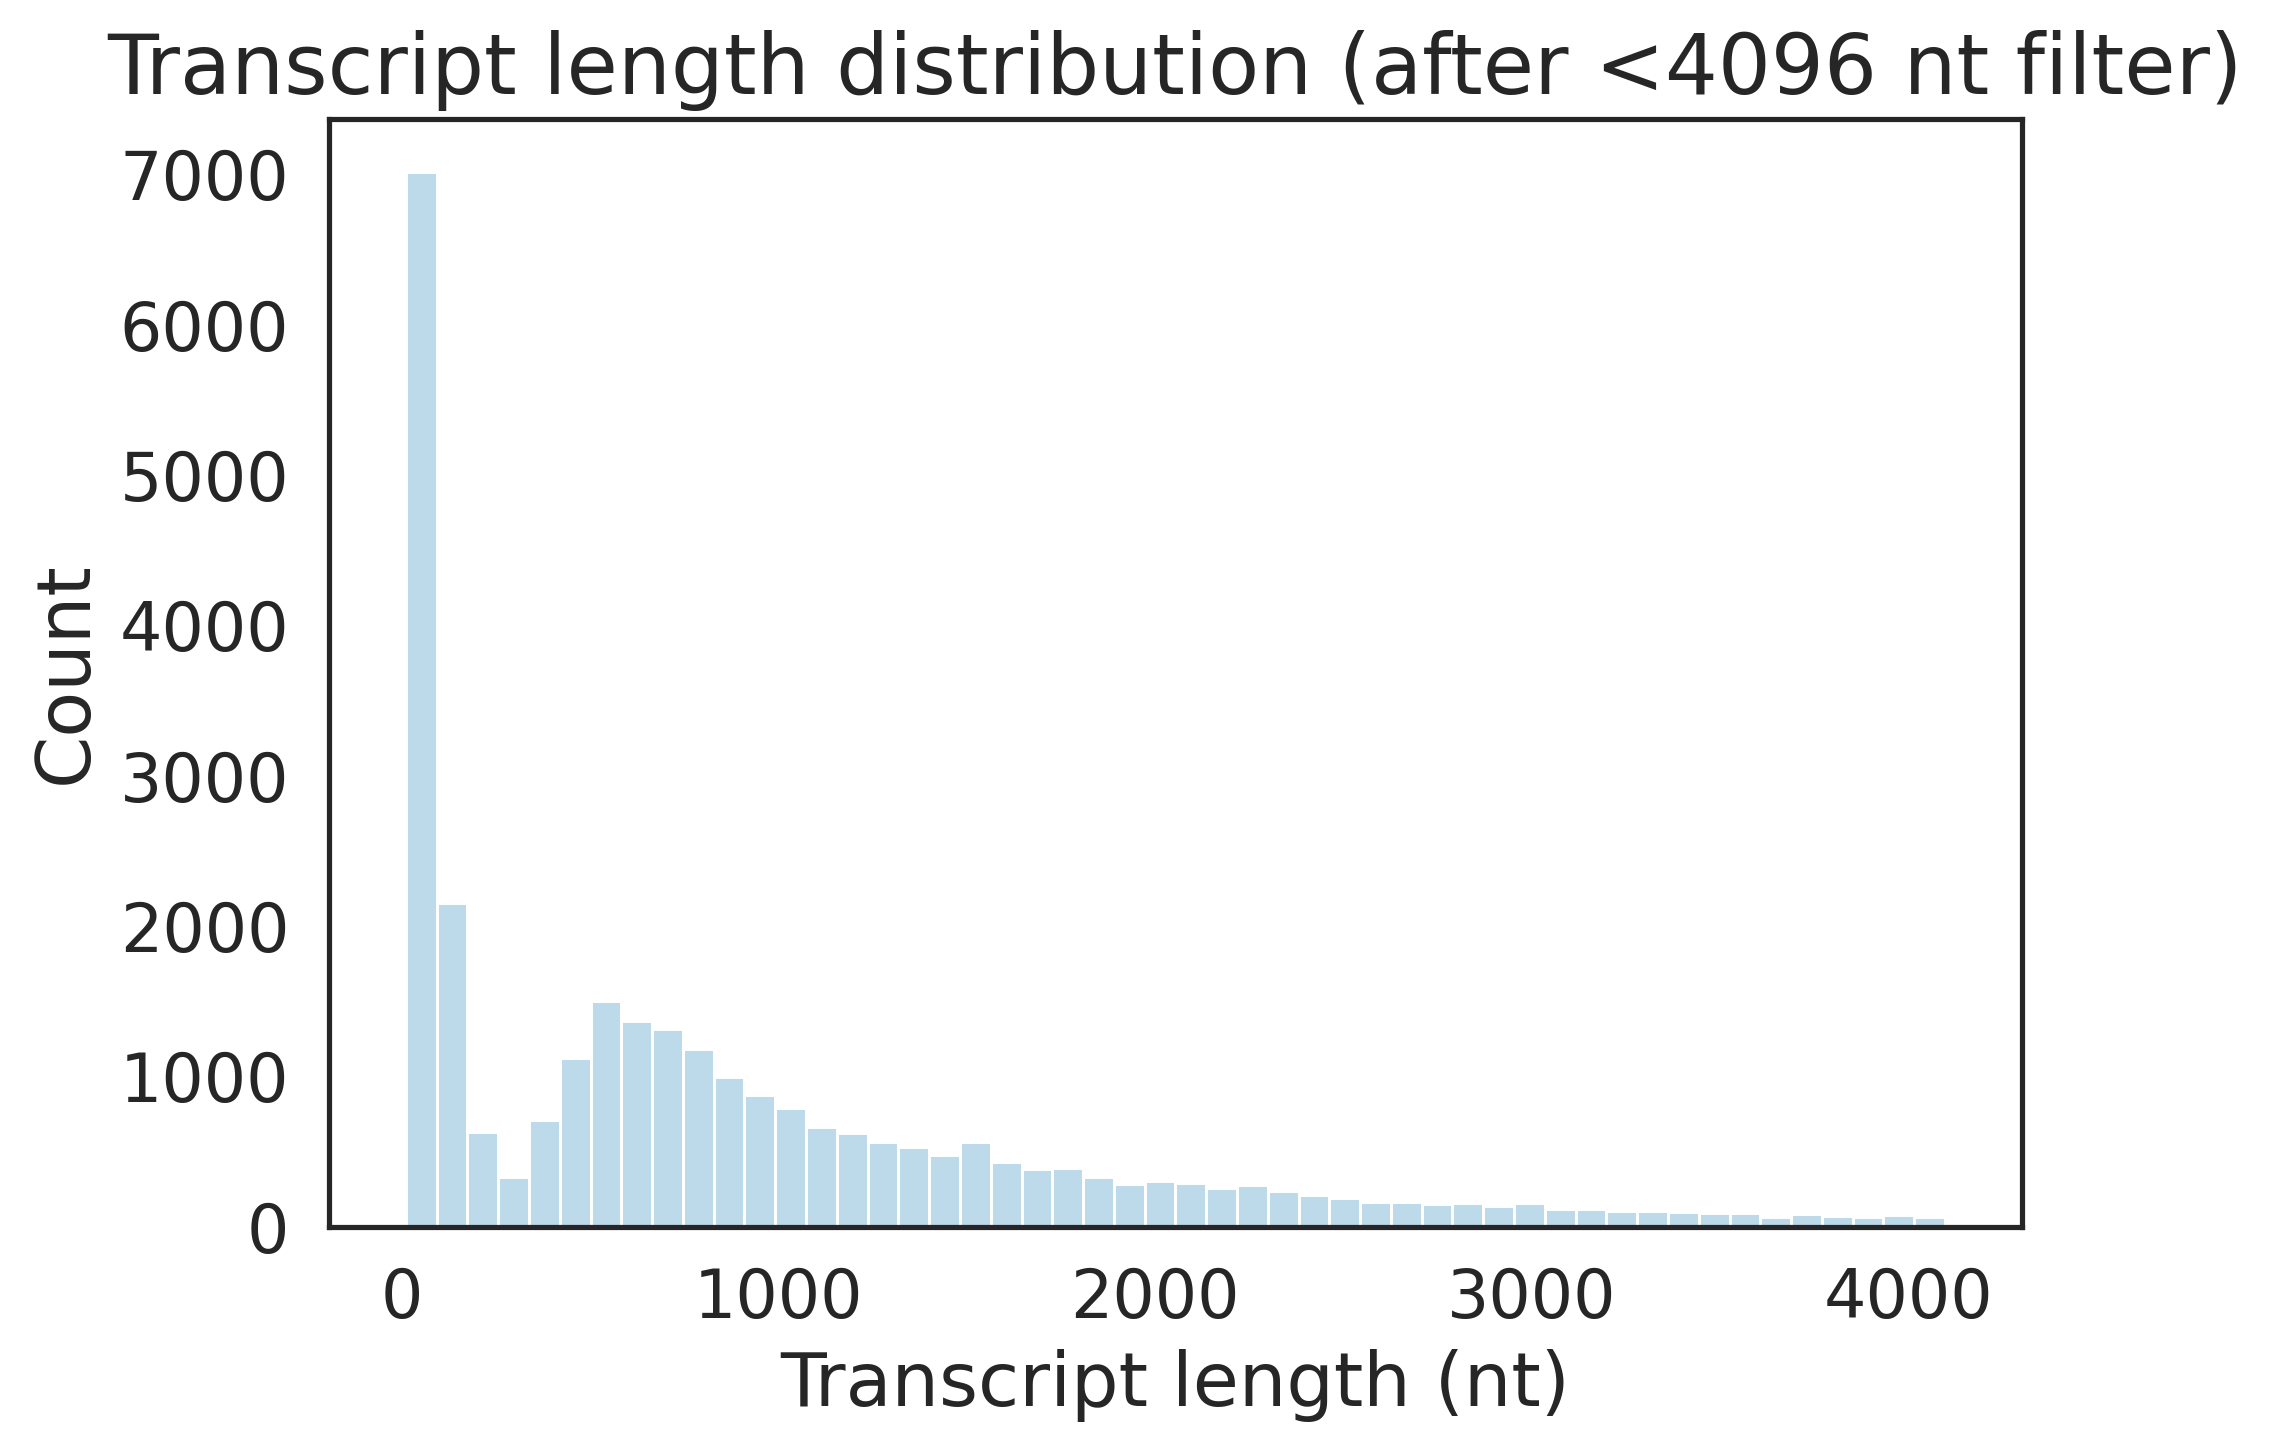

In [34]:
# ------------------------------------------------------------
# Summary of entities and sequences after length filtering
# ------------------------------------------------------------

# Number of unique RNA entities
n_entities_remaining = len(df_ncrna_unique)
print("Number of unique RNA entities remaining:", n_entities_remaining)

# Number of unique sequences across all entities
all_sequences = [s for seqs in df_ncrna_unique["seq_list_filtered_len"] for s in seqs]
n_sequences_remaining = len(set(all_sequences))
print("Number of unique sequences remaining:", n_sequences_remaining)

# Optional: transcript length distribution as before
all_lengths = [len(s) for s in all_sequences]
all_lengths = np.array(all_lengths)

print("\n=== Transcript length distribution after filtering ===")
print("Number of transcripts:", len(all_lengths))
print("Min length:", all_lengths.min())
print("Max length:", all_lengths.max())
print("Mean length:", all_lengths.mean())
print("Median length:", np.median(all_lengths))
print("25th percentile:", np.percentile(all_lengths, 25))
print("75th percentile:", np.percentile(all_lengths, 75))

# Plot histogram
plt.figure(figsize=(7,5), dpi=300)
sns.histplot(all_lengths, bins=50, color="#A6CEE3")
plt.xlabel("Transcript length (nt)")
plt.ylabel("Count")
plt.title("Transcript length distribution (after <4096 nt filter)")
plt.tight_layout()
plt.show()
plt.close()